# Notebook 04 — Best-found perfect-foresight cooling benchmark (OC) and LP lower bound

Stage 4. Code: `src/optimal_control.py` (problem $\mathcal P_d$, LP bound, IPOPT/HiGHS calls, independent checks, command replay), reusing the plant (`src/thermal_model.py`) and the Stage 3 simulator and metrics (`src/controllers.py`).

<div style="background:#fff4e5;border-left:6px solid #eb6834;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Scope and claim discipline</b><br>
<ul><li><b>Offline benchmark, not a controller.</b> The optimiser is given the whole future load and outdoor-temperature trace. No real controller knows this, so OC cannot be deployed. It shows what is achievable <i>in this model</i> with perfect foresight.</li><li>Results are <b>best-found</b> local solutions from a few starts. They are <b>never</b> claimed to be globally optimal.</li><li>Each OC problem uses the same start and end state as one PI controller, and is compared <b>only</b> with that controller (B1-protocol vs B1, B2-protocol vs B2). Results from different boundary protocols are never compared with each other.</li><li>Two numbers are kept apart: the optimiser's discrete objective $J_d$, and the cooling electricity integrated along the replayed continuous trajectory. Only the second is an electricity result.</li><li>A signed saving is claimed only when <b>both</b> the PI run and the OC replay are complete, stay within limits on the 5 s grid, and pass the terminal checks. Otherwise the numbers are descriptive.</li><li>Every number is a <b>model result with illustrative [ILL] parameters</b>, not a real-facility validation.</li></ul>
</div>

<div style="background:#f1f1ef;border-left:6px solid #6b6b66;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>AI acknowledgement</b><br>
Drafted by Claude (Anthropic), used through Claude Code, at the team's request on 29 Oct 2026. The team must review it and be able to explain it. See <code>AI_USE_LOG.md</code>.
</div>

In [1]:
import json
import re
import sys
import time
from pathlib import Path

import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
import casadi

sys.path.insert(0, str(Path("..", "src").resolve()))
import thermal_model as tm
import controllers as ct
import optimal_control as oc

FIG_DIR = Path("..", "figures").resolve()
FIG_DIR.mkdir(exist_ok=True)
p = tm.Params()
H = 3600.0
T_NB_START = time.perf_counter()

# ---- declared before any optimisation run ----
HORIZON = 17 * H            # identical to Stage 3
FINE_DT = 5.0               # replay / inspection grid, identical to Stage 3
DTS = (300, 60)             # 300 s first, then 60 s
T_A_BAND, T_S_MAX = (18.0, 27.0), 40.0
TOL_SAFETY = 1e-6           # K, identical to Stage 3
TOL_TERMINAL = 1e-3         # K, identical to Stage 3
TOL_DU = 1e-4               # |dU| max g <= TOL_DU E_cool, identical to Stage 3
TOL_FEAS_K, TOL_FEAS_W = 1e-6, 1e-3   # a point is feasible for P_d if every residual/violation is within these
TOL_REPLAY = 1e-6           # K: replayed state at update times vs optimiser state
TOL_OBJ = 1e-9              # relative: solver objective vs independent re-evaluation of J_d
TOL_LP = 1e-7               # relative: agreement of HiGHS configurations, and LP objective vs certified dual bound
TOL_INV = 1e-6              # relative: constant-COP invariance
NLP_WALL_S, NLP_MAX_ITER, LP_TIME_S = 300.0, 3000, 600.0   # per-solve budget (IPOPT max_wall_time / max_iter; HiGHS time limit)
STAGE_BUDGET_MIN = 60.0     # whole-notebook budget; exceeding it is reported
SEEDS, PERTURB = (1, 2, 3), 0.10   # three reproducible perturbed starts: +10 % of Q_max white noise (seeded)
ISC_DT = 5.0                # variant OC-ISC5: limits also imposed every 5 s inside each update interval

results, findings = [], []


def record(cid, desc, value, criterion, passed):
    # non-fatal: every check is logged and the summary at the end reports PASS/FAIL truthfully
    results.append((cid, desc, value, criterion, bool(passed)))
    print(f"[{'PASS' if passed else 'FAIL'}] {cid}: {desc}\n        measured: {value}   criterion: {criterion}")


def finding(fid, text):
    findings.append((fid, text))
    print(f"[FINDING] {fid}: {text}")


print(f"numpy {np.__version__}, scipy {scipy.__version__} (HiGHS via scipy.optimize.linprog), casadi {casadi.__version__} "
      f"(bundled IPOPT, MUMPS), matplotlib {matplotlib.__version__}")
print(f"horizon {HORIZON/H:.0f} h; update intervals {DTS} s; replay grid {FINE_DT} s; limits: air {T_A_BAND[0]}-{T_A_BAND[1]} C, "
      f"equipment <= {T_S_MAX} C (illustrative)")
print(f"tolerances: safety {TOL_SAFETY} K, terminal {TOL_TERMINAL} K, dU {TOL_DU:.0e} E_cool, feasibility {TOL_FEAS_K} K / {TOL_FEAS_W} W, "
      f"replay {TOL_REPLAY} K, objective {TOL_OBJ:.0e}, LP {TOL_LP:.0e}, invariance {TOL_INV:.0e}")
print(f"budget: {NLP_WALL_S:.0f} s and {NLP_MAX_ITER} iterations per NLP solve; {LP_TIME_S:.0f} s per LP; {STAGE_BUDGET_MIN:.0f} min for the notebook")
print(f"starts: warm start + seeds {SEEDS} (perturbation {PERTURB:.0%} of Q_max)")

numpy 2.5.4, scipy 1.18.1 (HiGHS via scipy.optimize.linprog), casadi 3.8.2 (bundled IPOPT, MUMPS), matplotlib 3.11.2
horizon 17 h; update intervals (300, 60) s; replay grid 5.0 s; limits: air 18.0-27.0 C, equipment <= 40.0 C (illustrative)
tolerances: safety 1e-06 K, terminal 0.001 K, dU 1e-04 E_cool, feasibility 1e-06 K / 0.001 W, replay 1e-06 K, objective 1e-09, LP 1e-07, invariance 1e-06
budget: 300 s and 3000 iterations per NLP solve; 600 s per LP; 60 min for the notebook
starts: warm start + seeds (1, 2, 3) (perturbation 10% of Q_max)


## 1. The optimisation problem $\mathcal P_d$ (spec §7.4)
<div style="background:#e8f1fc;border-left:6px solid #2a78d6;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Discretised problem, one per scenario × update interval × boundary protocol</b><br>
Update grid $t_k=k\,\Delta t$, $k=0,\dots,N$, with $N=17\,\mathrm{h}/\Delta t$ ($N=204$ at 300 s, $1020$ at 60 s). The load and outdoor temperature change only at 1 h and 9 h, which lie on both grids, so they are constant on every interval.<ul><li><b>Variables:</b> commands $u_k=Q_{c,k}$ (W$_{th}$, held on $[t_k,t_{k+1})$) and states $x_k=[T_{s,k},T_{a,k}]$ (°C). Both are decision variables (simultaneous, sparse form).</li><li><b>Dynamics:</b> $x_{k+1}=\Phi x_k+\Gamma\,[u_k,\ P_{IT,k},\ T_{out,k}]^\top$, the exact ZOH matrices from <code>thermal_model.zoh_step_matrices</code>.</li><li><b>Boundary:</b> $x_0=x_N=$ the start state of the matched PI run (its own equilibrium, as in Stage 3).</li><li><b>Limits at the sample points:</b> $0\le u_k\le Q_{\max}$, $18\le T_{a,k}\le 27$ °C, $T_{s,k}\le 40$ °C.</li><li><b>Objective:</b> $J_d=\sum_{k=0}^{N-1}\Delta t\;u_k\,/\,\mathrm{COP}(T_{a,k},T_{out,k})$, in J$_e$, reported in kWh$_e$. This is a left-endpoint rule: each interval's electricity is charged at the COP of its <i>starting</i> air temperature.</li></ul><b>Variant OC-ISC5 (separately labelled):</b> the same limits are also imposed every 5 s <i>inside</i> each interval. The state at $t_k+\tau$ is an exact linear function of $(x_k,u_k)$, $x(t_k+\tau)=\Phi(\tau)x_k+\Gamma(\tau)w_k$, so these remain linear constraints. The objective is unchanged.
</div>

<div style="background:#e8f1fc;border-left:6px solid #2a78d6;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>LP lower bound, and what its gap means</b><br>
On the COP domain, $g=1/\mathrm{COP}$ is strictly decreasing in $T_a$: $\partial g/\partial T_a=-T_{cd}/(\eta_{II}T_{ev}^2)<0$. Every feasible point has $u_k\ge 0$ and $T_{a,k}\le 27$ °C, so term by term $u_k\,g(T_{a,k},T_{out,k})\ge u_k\,g(27,T_{out,k})$.<br>Replacing $g$ by $g(27,T_{out,k})$ gives an LP with the <b>same</b> matrices, limits and boundary conditions. Its optimum satisfies $J_{LB}\le J_d^\ast\le J_d(\text{best-found})$.<ul><li>The relative gap $(J_d(\text{best})-J_{LB})/J_{LB}$ bounds how far the best-found point can be from the optimum of $\mathcal P_d$ <b>in $J_d$ only</b>.</li><li>It says nothing about continuous-time electricity, and nothing about safety between samples.</li><li>The bound is <b>certified</b> here by weak duality: from HiGHS's equality multipliers $y$, we compute $b^\top y+\sum_i\min(r_il_i,r_iu_i)$ ourselves, with $r=c-A^\top y$. That is a valid lower bound for <i>any</i> $y$, whatever the solver's status text says.</li></ul>
</div>

## 2. Matched PI runs (Stage 3 code, unchanged) and a check that they reproduce Stage 3

The PI runs are re-created with exactly the Stage 3 functions and settings: the same traces, horizon, gains, own-equilibrium start and 5 s grid. They are then checked against the numbers printed in notebook 03.

In [2]:
PD = ct.PiecewiseDisturbance
CMP = {
    "S1":  dict(dist=PD([0, 1*H, 9*H], [0.6e6, 1.0e6, 0.6e6], [30.0, 30.0, 30.0]), title="S1: load 0.6 → 1.0 MW at 1 h → 0.6 MW at 9 h ($T_{out}$ 30 °C)"),
    "S2c": dict(dist=PD([0, 1*H, 9*H], [0.8e6, 0.8e6, 0.8e6], [30.0, 35.0, 30.0]), title="S2c: load 0.8 MW; $T_{out}$ 30 → 35 °C at 1 h → 30 °C at 9 h"),
}


def make_ctrl(kind, dt, P0, pp=p):
    g = ct.STAGE2_GAINS[dt]
    if kind == "B1":
        return ct.FixedSetpointPI(g, 24.0, Q_min=0.0, Q_max=pp.Q_max)
    return ct.LoadAdaptivePI(g, ct.adaptive_setpoint(P0, pp.UA_s), Q_min=0.0, Q_max=pp.Q_max, UA_s=pp.UA_s)


def run(kind, dt, dist, t_end=HORIZON, fine_dt=FINE_DT):
    P0, To0 = dist.at(0.0)
    ctrl = make_ctrl(kind, dt, P0)
    Q0 = tm.holding_cooling(p, ctrl.T_set, P0, To0)
    x0 = tm.equilibrium(p, Q0, P0, To0)
    ctrl.initialize(Q0)
    res = ct.simulate_closed_loop(p, ctrl, dist, x0, t_end, fine_dt=fine_dt)
    res.meta["x0"], res.meta["Q0"] = x0, Q0
    return res


PI = {(sid, dt, kind): run(kind, dt, CMP[sid]["dist"]) for sid in CMP for dt in DTS for kind in ("B1", "B2")}

nb3 = json.loads(Path("03_load_adaptive_pi_energy.ipynb").read_text())
txt3 = "\n".join("".join(o.get("text", "")) for c in nb3["cells"] if c["cell_type"] == "code" for o in c.get("outputs", []))
S3 = {(m[1], int(m[2]), m[3]): (m[4], m[5], m[6])
      for m in re.finditer(r"^(S1|S2c) (60|300)s (B1|B2)\s+(\d+\.\d)\s+(\d+\.\d)\s+(\d+\.\d)", txt3, re.M)}
for key, r in PI.items():
    e = ct.energy_summary(p, r)
    now = (f"{e['E_cool_kWh_e']:.1f}", f"{e['E_Q_kWh_th']:.1f}", f"{e['E_IT_kWh_e']:.1f}")
    record(f"PI0-{key[0]}-{key[1]}-{key[2]}", f"{key[0]} dt={key[1]}s {key[2]}: re-created PI run reproduces Stage 3 (E_cool, E_Q, E_IT)",
           f"now {now}, notebook 03 {S3.get(key)}", "identical to the printed 0.1 kWh", S3.get(key) == now)

[PASS] PI0-S1-300-B1: S1 dt=300s B1: re-created PI run reproduces Stage 3 (E_cool, E_Q, E_IT)
        measured: now ('2756.7', '13604.0', '13400.0'), notebook 03 ('2756.7', '13604.0', '13400.0')   criterion: identical to the printed 0.1 kWh
[PASS] PI0-S1-300-B2: S1 dt=300s B2: re-created PI run reproduces Stage 3 (E_cool, E_Q, E_IT)
        measured: now ('2656.2', '13568.0', '13400.0'), notebook 03 ('2656.2', '13568.0', '13400.0')   criterion: identical to the printed 0.1 kWh
[PASS] PI0-S1-60-B1: S1 dt=60s B1: re-created PI run reproduces Stage 3 (E_cool, E_Q, E_IT)
        measured: now ('2756.5', '13604.0', '13400.0'), notebook 03 ('2756.5', '13604.0', '13400.0')   criterion: identical to the printed 0.1 kWh
[PASS] PI0-S1-60-B2: S1 dt=60s B2: re-created PI run reproduces Stage 3 (E_cool, E_Q, E_IT)
        measured: now ('2656.2', '13568.0', '13400.0'), notebook 03 ('2656.2', '13568.0', '13400.0')   criterion: identical to the printed 0.1 kWh
[PASS] PI0-S2c-300-B1: S2c dt=300s B1: r

## 3. Building $\mathcal P_d$ and verifying it **before** solving

| ID | Check |
|---|---|
| DYN | Feed the PI commands through Stage 1's `simulate_zoh` (independent of the problem assembly). The resulting states must satisfy every dynamics row of $\mathcal P_d$. For OC-ISC5, every intersample row must reproduce `simulate_zoh` **restarted from that interval's start state** $x_k$ and stepped every 5 s |
| GX | The COP expression used inside the NLP (no domain checks) equals `1/thermal_model.cop` across the band |
| LB | `cop()` is valid over the **whole** air band at every outdoor temperature in the trace; $g$ is strictly decreasing on a dense grid; the analytic derivative is negative; so $g(27,T_{out})$ is a genuine minimum |

**Correction disclosed (DYN for OC-ISC5).** The first full run compared the intersample rows with **one uninterrupted** 5 s propagation over the whole 17 h. That failed in all 8 OC-ISC5 problems, by 3–6e-8 K against the 1e-9 K criterion.

- The rows are defined from each interval's own start state $x_k$. The uninterrupted reference instead accumulates round-off over about 12 000 steps, and drifts from the update-interval propagation by the **same** 3–6e-8 K at the update times, where the intersample rows play no part.
- Restarting the reference at each $x_k$ gives agreement to about 1e-12 K. The criterion is unchanged at 1e-9 K.
- The whole-horizon drift is still printed with each DYN line, as information.

In [3]:
VARIANTS = {"OC": None, "OC-ISC5": ISC_DT}
PROB = {}
for (sid, dt, kind), r in PI.items():
    for var, isd in VARIANTS.items():
        PROB[(sid, dt, kind, var)] = oc.build_problem(
            p, CMP[sid]["dist"], r.meta["x0"], HORIZON, dt, T_a_band=T_A_BAND, T_s_max=T_S_MAX, intersample_dt=isd,
            label=f"{sid} {dt}s {kind}-protocol {var}")
for dt in DTS:
    for var in VARIANTS:
        pr = PROB[("S1", dt, "B1", var)]
        n_in = 0 if pr.A_in is None else pr.A_in.shape[0]
        print(f"{var:8s} dt={dt:3d}s: N={pr.N}, {pr.n} variables, {pr.A_eq.shape[0]} equality rows, {n_in} intersample rows")


def pi_point(res):
    # PI commands and the states seen at the update times, plus the final state
    return res.log["u"].copy(), np.vstack([np.column_stack([res.log["T_s"], res.log["T_a"]]), res.X[-1, :2]])


for key, prob in PROB.items():
    u, _ = pi_point(PI[key[:3]])
    X = tm.simulate_zoh(p, prob.x_start, prob.t, np.column_stack([u, prob.P_IT, prob.T_out]))
    z = prob.join(u, X[:, :2])
    dyn = float(np.max(np.abs((prob.A_eq @ z - prob.b_eq)[2:-2])))
    ok, msg = dyn < 1e-9, f"dynamics rows {dyn:.1e} K"
    if prob.A_in is not None:
        # Each intersample row is defined from its own interval's start state x_k, so the reference restarts
        # simulate_zoh at every x_k and steps through the interval every ISC_DT seconds.
        m = int(round(prob.dt / ISC_DT))
        rows = prob.A_in @ z + prob.c_in
        d_in = 0.0
        for kk in range(prob.N):
            sub = kk * prob.dt + ISC_DT * np.arange(m + 1)
            Xs = tm.simulate_zoh(p, X[kk, :2], sub, np.tile([u[kk], prob.P_IT[kk], prob.T_out[kk]], (m, 1)))
            sel = slice(kk * (m - 1) * 2, (kk + 1) * (m - 1) * 2)
            d_in = max(d_in, float(np.max(np.abs(rows[sel] - Xs[1:m, :2].reshape(-1)))))
        # Reported, not tested: one uninterrupted 5 s propagation over the whole horizon drifts from the
        # update-interval propagation by round-off accumulated over ~12 000 steps.
        fine = np.unique(np.concatenate([np.arange(0.0, HORIZON + 1e-9, ISC_DT), prob.t]))
        k = np.searchsorted(prob.t, fine[:-1], side="right") - 1
        Xf = tm.simulate_zoh(p, prob.x_start, fine, np.column_stack([u[k], prob.P_IT[k], prob.T_out[k]]))
        drift = float(np.max(np.abs(Xf[np.searchsorted(fine, prob.t), :2] - X[:, :2])))
        ok, msg = ok and d_in < 1e-9, msg + (f"; {prob.A_in.shape[0]} intersample rows {d_in:.1e} K "
                                             f"[info: whole-horizon 5 s vs {prob.dt:.0f} s propagation drift {drift:.1e} K]")
    record(f"DYN-{'-'.join(map(str, key))}", f"{prob.label}: problem rows reproduce Stage 1 simulate_zoh under the PI commands",
           msg, "< 1e-9 K", ok)

Tg = np.linspace(*T_A_BAND, 901)
gx = max(float(np.max(np.abs(oc.inv_cop_expr(p, Tg, To) * tm.cop(p, Tg, np.full_like(Tg, To)) - 1.0))) for To in (30.0, 35.0))
record("GX", "NLP's 1/COP expression equals 1/thermal_model.cop over 18-27 C at T_out 30 and 35 C", f"max rel diff {gx:.1e}", "< 1e-12", gx < 1e-12)

for key, prob in PROB.items():
    if key[3] != "OC":
        continue      # the variant has the same T_out trace and band, hence the same coefficients
    ok, info = oc.check_bound_coefficients(prob)
    g_lb = oc.bound_coefficients(prob)
    record(f"LB-{key[0]}-{key[1]}-{key[2]}", f"{prob.label}: LP coefficient 1/COP(27 C, T_out) is a valid minimum over the whole band "
           f"(T_out values {info.get('T_out_values')})",
           f"min over band of g - g_LB = {info.get('min_g_minus_gLB', np.nan):.2e}; max dg/dT_a = {info.get('max_dg_dTa', np.nan):.2e} 1/K; "
           f"COP(27 C) = {1/g_lb.min():.3f}..{1/g_lb.max():.3f}", ">= 0, < 0, cop() valid on 9001 points", ok)

OC       dt=300s: N=204, 614 variables, 412 equality rows, 0 intersample rows
OC-ISC5  dt=300s: N=204, 614 variables, 412 equality rows, 24072 intersample rows
OC       dt= 60s: N=1020, 3062 variables, 2044 equality rows, 0 intersample rows
OC-ISC5  dt= 60s: N=1020, 3062 variables, 2044 equality rows, 22440 intersample rows
[PASS] DYN-S1-300-B1-OC: S1 300s B1-protocol OC: problem rows reproduce Stage 1 simulate_zoh under the PI commands
        measured: dynamics rows 7.1e-15 K   criterion: < 1e-9 K
[PASS] DYN-S1-300-B1-OC-ISC5: S1 300s B1-protocol OC-ISC5: problem rows reproduce Stage 1 simulate_zoh under the PI commands
        measured: dynamics rows 7.1e-15 K; 24072 intersample rows 3.5e-12 K [info: whole-horizon 5 s vs 300 s propagation drift 3.9e-08 K]   criterion: < 1e-9 K
[PASS] DYN-S1-300-B2-OC: S1 300s B2-protocol OC: problem rows reproduce Stage 1 simulate_zoh under the PI commands
        measured: dynamics rows 8.9e-15 K   criterion: < 1e-9 K


[PASS] DYN-S1-300-B2-OC-ISC5: S1 300s B2-protocol OC-ISC5: problem rows reproduce Stage 1 simulate_zoh under the PI commands
        measured: dynamics rows 8.9e-15 K; 24072 intersample rows 2.7e-12 K [info: whole-horizon 5 s vs 300 s propagation drift 3.4e-08 K]   criterion: < 1e-9 K
[PASS] DYN-S1-60-B1-OC: S1 60s B1-protocol OC: problem rows reproduce Stage 1 simulate_zoh under the PI commands
        measured: dynamics rows 1.6e-11 K   criterion: < 1e-9 K
[PASS] DYN-S1-60-B1-OC-ISC5: S1 60s B1-protocol OC-ISC5: problem rows reproduce Stage 1 simulate_zoh under the PI commands
        measured: dynamics rows 1.6e-11 K; 22440 intersample rows 1.4e-13 K [info: whole-horizon 5 s vs 60 s propagation drift 4.0e-08 K]   criterion: < 1e-9 K
[PASS] DYN-S1-60-B2-OC: S1 60s B2-protocol OC: problem rows reproduce Stage 1 simulate_zoh under the PI commands
        measured: dynamics rows 1.3e-11 K   criterion: < 1e-9 K


[PASS] DYN-S1-60-B2-OC-ISC5: S1 60s B2-protocol OC-ISC5: problem rows reproduce Stage 1 simulate_zoh under the PI commands
        measured: dynamics rows 1.3e-11 K; 22440 intersample rows 1.3e-13 K [info: whole-horizon 5 s vs 60 s propagation drift 3.4e-08 K]   criterion: < 1e-9 K
[PASS] DYN-S2c-300-B1-OC: S2c 300s B1-protocol OC: problem rows reproduce Stage 1 simulate_zoh under the PI commands
        measured: dynamics rows 1.1e-14 K   criterion: < 1e-9 K
[PASS] DYN-S2c-300-B1-OC-ISC5: S2c 300s B1-protocol OC-ISC5: problem rows reproduce Stage 1 simulate_zoh under the PI commands
        measured: dynamics rows 1.1e-14 K; 24072 intersample rows 4.8e-12 K [info: whole-horizon 5 s vs 300 s propagation drift 5.8e-08 K]   criterion: < 1e-9 K
[PASS] DYN-S2c-300-B2-OC: S2c 300s B2-protocol OC: problem rows reproduce Stage 1 simulate_zoh under the PI commands
        measured: dynamics rows 1.1e-14 K   criterion: < 1e-9 K


[PASS] DYN-S2c-300-B2-OC-ISC5: S2c 300s B2-protocol OC-ISC5: problem rows reproduce Stage 1 simulate_zoh under the PI commands
        measured: dynamics rows 1.1e-14 K; 24072 intersample rows 4.0e-12 K [info: whole-horizon 5 s vs 300 s propagation drift 4.5e-08 K]   criterion: < 1e-9 K
[PASS] DYN-S2c-60-B1-OC: S2c 60s B1-protocol OC: problem rows reproduce Stage 1 simulate_zoh under the PI commands
        measured: dynamics rows 2.2e-11 K   criterion: < 1e-9 K
[PASS] DYN-S2c-60-B1-OC-ISC5: S2c 60s B1-protocol OC-ISC5: problem rows reproduce Stage 1 simulate_zoh under the PI commands
        measured: dynamics rows 2.2e-11 K; 22440 intersample rows 2.0e-13 K [info: whole-horizon 5 s vs 60 s propagation drift 5.9e-08 K]   criterion: < 1e-9 K
[PASS] DYN-S2c-60-B2-OC: S2c 60s B2-protocol OC: problem rows reproduce Stage 1 simulate_zoh under the PI commands
        measured: dynamics rows 1.7e-11 K   criterion: < 1e-9 K


[PASS] DYN-S2c-60-B2-OC-ISC5: S2c 60s B2-protocol OC-ISC5: problem rows reproduce Stage 1 simulate_zoh under the PI commands
        measured: dynamics rows 1.7e-11 K; 22440 intersample rows 1.7e-13 K [info: whole-horizon 5 s vs 60 s propagation drift 4.6e-08 K]   criterion: < 1e-9 K
[PASS] GX: NLP's 1/COP expression equals 1/thermal_model.cop over 18-27 C at T_out 30 and 35 C
        measured: max rel diff 2.2e-16   criterion: < 1e-12
[PASS] LB-S1-300-B1: S1 300s B1-protocol OC: LP coefficient 1/COP(27 C, T_out) is a valid minimum over the whole band (T_out values [30.])
        measured: min over band of g - g_LB = 0.00e+00; max dg/dT_a = -8.33e-03 1/K; COP(27 C) = 5.638..5.638   criterion: >= 0, < 0, cop() valid on 9001 points
[PASS] LB-S1-300-B2: S1 300s B2-protocol OC: LP coefficient 1/COP(27 C, T_out) is a valid minimum over the whole band (T_out values [30.])
        measured: min over band of g - g_LB = 0.00e+00; max dg/dT_a = -8.33e-03 1/K; COP(27 C) = 5.638..5.638   criterion

## 4. Solving: LP bound (HiGHS) and NLP (IPOPT) from four starts
<div style="background:#e7f7f0;border-left:6px solid #1baf7a;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>Procedure for each problem</b><br>
<ol><li><b>LP:</b> solve with every HiGHS configuration in <code>oc.LP_METHODS</code> and log each status. During development, SciPy's default HiGHS path returned <i>status 4 / "Not Set"</i> on some of these LPs, so no single path is trusted. The reported $J_{LB}$ is the largest <b>certified dual bound</b> among the configurations that report optimal.</li><li><b>Warm start:</b> if the matched PI sequence (its commands plus the states at the updates) is feasible for this exact problem, start from it. Otherwise start from the feasible point nearest to the PI commands in the L1 sense (an LP), and disclose this.</li><li><b>Three perturbed starts</b> (seeds 1, 2, 3): the warm commands plus 10 % of $Q_{\max}$ white noise, clipped to $[0,Q_{\max}]$, with states propagated from $x_0$. These are generally infeasible; IPOPT moves them inside the bounds.</li><li><b>IPOPT</b> with the exact sparse Hessian (CasADi), MUMPS, tol 1e-9, constraint tolerance 1e-9, bounds honoured exactly (<code>bound_relax_factor = 0</code>), within the declared budget.</li><li>Every returned point is <b>re-checked independently</b>: the dynamics are recomputed from $\Phi,\Gamma$, the limits checked, and $J_d$ re-evaluated with the domain-checked <code>cop()</code>. The best-found point is the lowest $J_d$ among the independently feasible points. A solver output that fails this check is never used as an upper bound.</li></ol>
</div>

In [4]:
def solve_case(key):
    prob = PROB[key]
    lp, lp_att = oc.solve_lp(prob, time_limit=LP_TIME_S, tol_K=TOL_FEAS_K, tol_W=TOL_FEAS_W)
    nlp = oc.make_nlp(prob)
    u_pi, x_pi = pi_point(PI[key[:3]])
    chk_pi = oc.check_point(prob, u_pi, x_pi)
    pi_feas = oc.is_feasible(chk_pi, TOL_FEAS_K, TOL_FEAS_W)
    J_pi = oc.J_d(prob, u_pi, x_pi[:, 1])
    if pi_feas:
        z_w, warm = prob.join(u_pi, x_pi), "matched PI sequence (feasible for this problem)"
    else:
        z_w, info = oc.nearest_feasible_start(prob, u_pi, time_limit=LP_TIME_S)
        warm = (f"PI sequence is NOT feasible for this problem, so the warm start is the feasible point nearest to the PI commands "
                f"(L1 LP, HiGHS [{info['method']}], sum|u - u_PI| = {info['l1_MW']:.3f} MW)")
    u_w = prob.split(z_w)[0]
    starts = [("warm", z_w)] + [(f"seed{s}", oc.perturbed_start(prob, u_w, s, PERTURB)) for s in SEEDS]
    sols = [oc.solve_nlp(prob, z0, max_wall_time=NLP_WALL_S, max_iter=NLP_MAX_ITER, label=name, tol_K=TOL_FEAS_K,
                         tol_W=TOL_FEAS_W, nlp=nlp) for name, z0 in starts]
    feas = [s for s in sols if s.feasible]
    best = min(feas, key=lambda s: s.J_d) if feas else None
    return {"prob": prob, "lp": lp, "lp_att": lp_att, "nlp_data": nlp[1], "pi_feas": pi_feas, "chk_pi": chk_pi, "J_pi": J_pi,
            "warm": warm, "sols": sols, "best": best}


def print_case(key, c):
    prob, b = c["prob"], c["best"]
    n_in = 0 if prob.A_in is None else prob.A_in.shape[0]
    print(f"--- {prob.label}: {prob.n} variables, {prob.A_eq.shape[0]} equality + {n_in} intersample rows")
    ch = c["chk_pi"]
    print(f"    matched PI as a point of this problem: feasible = {c['pi_feas']}; sample-point violations T_a {ch['Ta_viol_K']:.3f} K, "
          f"T_s {ch['Ts_viol_K']:.3f} K, intersample rows {ch['inter_viol_K']:.3f} K, terminal {ch['term_K']:.1e} K; J_d(PI) = {c['J_pi']:.4f} kWh_e")
    print(f"    warm start: {c['warm']}")
    for a in c["lp_att"]:
        print(f"    LP  [{a.data['method']:22s}] {a.status[:60]:60s} {a.time_s:6.2f} s  J_LP {a.objective:12.6f}  "
              f"certified dual bound {a.data['dual_bound']:12.6f}  primal feasible {a.feasible}")
    for s in c["sols"]:
        viol = max(s.check["Ta_viol_K"], s.check["Ts_viol_K"], s.check["inter_viol_K"])
        print(f"    NLP {s.label:6s} {s.status:28s} it {s.iterations:4d} {s.time_s:7.2f} s  J_d solver {s.objective:11.5f} "
              f"re-eval {s.J_d:11.5f}  dyn {s.check['dyn_K']:.0e} K  limits {viol:.0e} K  u {s.check['u_viol_W']:.0e} W  "
              f"term {s.check['term_K']:.0e} K  feasible {s.feasible}")
    feas = [s for s in c["sols"] if s.feasible]
    if b is not None:
        J = np.array([s.J_d for s in feas])
        du = max(float(np.max(np.abs(s.u_W - b.u_W))) for s in feas)
        c["spread_rel"], c["spread_du"] = float((J.max() - J.min()) / J.min()), du
        print(f"    best-found J_d = {b.J_d:.5f} kWh_e (start '{b.label}'); {len(feas)}/{len(c['sols'])} starts feasible; "
              f"objective spread {(J.max()-J.min()):.2e} kWh_e ({c['spread_rel']:.1e} rel); max |u - u_best| over starts {du/1e3:.1f} kW_th")
        if c["lp"] is not None:
            jlb = c["lp"].data["dual_bound"]
            print(f"    J_LB = {jlb:.5f} kWh_e  ->  gap (J_d(best) - J_LB)/J_LB = {100*(b.J_d - jlb)/jlb:.3f} % (bounds suboptimality in J_d only)")
    else:
        print("    NO independently feasible NLP solution: no best-found value and no upper bound for this problem")


def verify_case(key, c):
    prob, lp, b, nd = c["prob"], c["lp"], c["best"], c["nlp_data"]
    tag = "-".join(map(str, key))
    # L5: LP and NLP built from the same arrays
    J = nd["jac_fun"](np.zeros(prob.n)).sparse()
    djac = float(abs(J - nd["A_all"]).max()) if J.nnz or nd["A_all"].nnz else 0.0
    m = prob.A_eq.shape[0]
    same = all(nd[k] is getattr(prob, k) for k in ("A_eq", "b_eq", "lb", "ub", "A_in"))
    same = same and lp is not None and all(lp.data[k] is getattr(prob, k) for k in ("A_eq", "b_eq", "lb", "ub", "A_in"))
    rhs = np.array_equal(nd["lbg"][:m], prob.b_eq) and np.array_equal(nd["ubg"][:m], prob.b_eq)
    if prob.A_in is not None:
        rhs = rhs and np.array_equal(nd["lbg"][m:], prob.lb_in) and np.array_equal(nd["ubg"][m:], prob.ub_in)
    c_lp = lp.data["c"] if lp is not None else np.zeros(prob.n)
    c_ok = (np.array_equal(c_lp[:prob.N], prob.dt * oc.U_SCALE * oc.bound_coefficients(prob) / tm.J_PER_KWH)
            and not np.any(c_lp[prob.N:]))
    record(f"L5-{tag}", f"{prob.label}: LP and NLP share the same matrices, right-hand sides and bounds; NLP constraint Jacobian = A",
           f"|J_NLP - A| = {djac:.1e}; same array objects {same}; rhs equal {rhs}; LP cost only on u, = dt g_LB {c_ok}",
           "0, True, True, True", djac == 0.0 and same and rhs and c_ok)
    # LP: status, agreement, certificate, feasibility
    good = [a for a in c["lp_att"] if a.solver_success]
    bad = [a for a in c["lp_att"] if not a.solver_success]
    if bad:
        finding(f"F-LP-{tag}", f"{prob.label}: HiGHS configuration(s) {[a.data['method'] for a in bad]} did not return optimal "
                f"({[a.status for a in bad]}); the bound uses the configurations that did")
    if good:
        objs = np.array([a.objective for a in good])
        agree = float((objs.max() - objs.min()) / objs.min())
        cert = max(abs(a.objective - a.data["dual_bound"]) / a.objective for a in good)
        record(f"LP-{tag}", f"{prob.label}: LP optimal in >= 1 HiGHS configuration; configurations agree; dual certificate matches; primal point feasible",
               f"{len(good)}/{len(c['lp_att'])} optimal; spread {agree:.1e}; |J_LP - dual bound|/J_LP {cert:.1e}; "
               f"eq residual {lp.data['eq_residual']:.1e}; independent feasibility {lp.feasible}",
               f"spread, certificate <= {TOL_LP:.0e}; feasible", agree <= TOL_LP and cert <= TOL_LP and lp.feasible)
    else:
        record(f"LP-{tag}", f"{prob.label}: LP solved", "no HiGHS configuration optimal", "optimal", False)
    # NLP best-found
    if b is None:
        record(f"NLP-{tag}", f"{prob.label}: an independently feasible NLP solution exists", "none", ">= 1", False)
        return
    rel = abs(b.objective - b.J_d) / b.J_d
    record(f"NLP-{tag}", f"{prob.label}: best-found point solver status, independent feasibility, objective re-evaluation",
           f"{b.status} ({b.label}); feasible {b.feasible}; |J solver - J_d re-eval|/J_d {rel:.1e}",
           f"Solve_Succeeded, feasible, <= {TOL_OBJ:.0e}", b.status == "Solve_Succeeded" and b.feasible and rel <= TOL_OBJ)
    for s in c["sols"]:
        if s.status != "Solve_Succeeded" or not s.feasible:
            finding(f"F-NLP-{tag}-{s.label}", f"{prob.label}, start {s.label}: IPOPT '{s.status}' after {s.iterations} iterations, "
                    f"{s.time_s:.1f} s; independently feasible {s.feasible}")
    if lp is not None:
        jlb = lp.data["dual_bound"]
        record(f"BND-{tag}", f"{prob.label}: certified J_LB <= best-found J_d", f"{jlb:.5f} <= {b.J_d:.5f} kWh_e", "holds", jlb <= b.J_d)
    if c["pi_feas"]:
        record(f"PIJ-{tag}", f"{prob.label}: PI sequence is feasible for this problem, so best-found J_d must be no worse than J_d(PI)",
               f"J_d(OC) {b.J_d:.4f} vs J_d(PI) {c['J_pi']:.4f} kWh_e", "J_d(OC) <= J_d(PI)", b.J_d <= c["J_pi"] * (1 + 1e-12))
    else:
        finding(f"F-PIJ-{tag}", f"{prob.label}: PI sequence is infeasible for this problem (sample-point T_a over by "
                f"{c['chk_pi']['Ta_viol_K']:.3f} K, intersample rows {c['chk_pi']['inter_viol_K']:.3f} K), so no J_d ordering is expected or checked")


CASES = {}
SOLVE_TIME = {}

### 4a. 300 s updates (both variants)

In [5]:
t0 = time.perf_counter()
for var in VARIANTS:
    for sid in CMP:
        for kind in ("B1", "B2"):
            key = (sid, 300, kind, var)
            CASES[key] = solve_case(key)
            print_case(key, CASES[key])
            verify_case(key, CASES[key])
SOLVE_TIME[300] = time.perf_counter() - t0
print(f"\n300 s: all solves took {SOLVE_TIME[300]:.1f} s wall time")

--- S1 300s B1-protocol OC: 614 variables, 412 equality + 0 intersample rows
    matched PI as a point of this problem: feasible = False; sample-point violations T_a 0.436 K, T_s 0.000 K, intersample rows 0.000 K, terminal 1.5e-09 K; J_d(PI) = 2755.6002 kWh_e
    warm start: PI sequence is NOT feasible for this problem, so the warm start is the feasible point nearest to the PI commands (L1 LP, HiGHS [highs (default)], sum|u - u_PI| = 0.021 MW)
    LP  [highs (default)       ] (HiGHS Status 0: Not Set)                                      0.01 s  J_LP          nan  certified dual bound          nan  primal feasible False
    LP  [highs-ipm             ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.01 s  J_LP  2400.804444  certified dual bound  2400.804444  primal feasible True
    LP  [highs-ds, no presolve ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.01 s  J_LP  2400.804444  certified dual bound  2400.804444  primal feasible True
    NLP warm  

--- S2c 300s B1-protocol OC: 614 variables, 412 equality + 0 intersample rows
    matched PI as a point of this problem: feasible = True; sample-point violations T_a 0.000 K, T_s 0.000 K, intersample rows 0.000 K, terminal 2.1e-09 K; J_d(PI) = 3069.4443 kWh_e
    warm start: matched PI sequence (feasible for this problem)
    LP  [highs (default)       ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.01 s  J_LP  2695.054935  certified dual bound  2695.054935  primal feasible True
    LP  [highs-ipm             ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.01 s  J_LP  2695.054935  certified dual bound  2695.054935  primal feasible True
    LP  [highs-ds, no presolve ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.01 s  J_LP  2695.054935  certified dual bound  2695.054935  primal feasible True
    NLP warm   Solve_Succeeded              it    8    0.01 s  J_d solver  2701.61926 re-eval  2701.61926  dyn 2e-14 K  limits 0e+00 K  u 0

--- S1 300s B1-protocol OC-ISC5: 614 variables, 412 equality + 24072 intersample rows
    matched PI as a point of this problem: feasible = False; sample-point violations T_a 0.436 K, T_s 0.000 K, intersample rows 0.369 K, terminal 1.5e-09 K; J_d(PI) = 2755.6002 kWh_e
    warm start: PI sequence is NOT feasible for this problem, so the warm start is the feasible point nearest to the PI commands (L1 LP, HiGHS [highs-ipm], sum|u - u_PI| = 0.021 MW)
    LP  [highs (default)       ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.36 s  J_LP  2400.853131  certified dual bound  2400.853130  primal feasible False
    LP  [highs-ipm             ] The HiGHS status code was not recognized. (HiGHS Status 15:    2.11 s  J_LP          nan  certified dual bound          nan  primal feasible False
    LP  [highs-ds, no presolve ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.12 s  J_LP  2400.853130  certified dual bound  2400.853130  primal feasible True
    NLP wa

--- S1 300s B2-protocol OC-ISC5: 614 variables, 412 equality + 24072 intersample rows
    matched PI as a point of this problem: feasible = True; sample-point violations T_a 0.000 K, T_s 0.000 K, intersample rows 0.000 K, terminal 1.2e-09 K; J_d(PI) = 2655.6099 kWh_e
    warm start: matched PI sequence (feasible for this problem)
    LP  [highs (default)       ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.39 s  J_LP  2400.670488  certified dual bound  2400.670488  primal feasible False
    LP  [highs-ipm             ] Optimization terminated successfully. (HiGHS Status 7: Optim   1.84 s  J_LP  2400.670488  certified dual bound  2400.670486  primal feasible True
    LP  [highs-ds, no presolve ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.13 s  J_LP  2400.670488  certified dual bound  2400.670488  primal feasible True
    NLP warm   Solve_Succeeded              it   61    6.28 s  J_d solver  2535.88415 re-eval  2535.88415  dyn 1e-14 K  limits 0e+

--- S2c 300s B1-protocol OC-ISC5: 614 variables, 412 equality + 24072 intersample rows
    matched PI as a point of this problem: feasible = True; sample-point violations T_a 0.000 K, T_s 0.000 K, intersample rows 0.000 K, terminal 2.1e-09 K; J_d(PI) = 3069.4443 kWh_e
    warm start: matched PI sequence (feasible for this problem)
    LP  [highs (default)       ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.18 s  J_LP  2695.054935  certified dual bound  2695.054935  primal feasible True
    LP  [highs-ipm             ] Optimization terminated successfully. (HiGHS Status 7: Optim   2.17 s  J_LP  2695.054935  certified dual bound  2695.054935  primal feasible True
    LP  [highs-ds, no presolve ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.10 s  J_LP  2695.054935  certified dual bound  2695.054935  primal feasible True
    NLP warm   Solve_Succeeded              it   37    3.98 s  J_d solver  2701.61926 re-eval  2701.61926  dyn 1e-14 K  limits 0e+

--- S2c 300s B2-protocol OC-ISC5: 614 variables, 412 equality + 24072 intersample rows
    matched PI as a point of this problem: feasible = True; sample-point violations T_a 0.000 K, T_s 0.000 K, intersample rows 0.000 K, terminal 1.6e-09 K; J_d(PI) = 2819.3040 kWh_e
    warm start: matched PI sequence (feasible for this problem)
    LP  [highs (default)       ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.18 s  J_LP  2694.872523  certified dual bound  2694.872523  primal feasible True
    LP  [highs-ipm             ] Optimization terminated successfully. (HiGHS Status 7: Optim   1.96 s  J_LP  2694.872523  certified dual bound  2694.872523  primal feasible True
    LP  [highs-ds, no presolve ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.08 s  J_LP  2694.872523  certified dual bound  2694.872523  primal feasible True
    NLP warm   Solve_Succeeded              it   32    2.94 s  J_d solver  2698.12797 re-eval  2698.12797  dyn 1e-14 K  limits 0e+

### 4b. 60 s updates (attempted after 300 s)

$N=1020$ intervals. If these solves do not converge reliably within the budget, the verified 300 s results stand and the limitation is reported here.

In [6]:
t0 = time.perf_counter()
for var in VARIANTS:
    for sid in CMP:
        for kind in ("B1", "B2"):
            key = (sid, 60, kind, var)
            CASES[key] = solve_case(key)
            print_case(key, CASES[key])
            verify_case(key, CASES[key])
SOLVE_TIME[60] = time.perf_counter() - t0
ok60 = all(CASES[k]["best"] is not None and CASES[k]["best"].status == "Solve_Succeeded" for k in CASES if k[1] == 60)
print(f"\n60 s: all solves took {SOLVE_TIME[60]:.1f} s wall time; every 60 s problem has a solved, feasible best-found point: {ok60}")
if not ok60:
    finding("F-60", "at least one 60 s problem has no solved feasible best-found point; use the 300 s results for those cases")

--- S1 60s B1-protocol OC: 3062 variables, 2044 equality + 0 intersample rows
    matched PI as a point of this problem: feasible = True; sample-point violations T_a 0.000 K, T_s 0.000 K, intersample rows 0.000 K, terminal 1.5e-09 K; J_d(PI) = 2756.4099 kWh_e
    warm start: matched PI sequence (feasible for this problem)
    LP  [highs (default)       ] (HiGHS Status 0: Not Set)                                      0.08 s  J_LP          nan  certified dual bound          nan  primal feasible False
    LP  [highs-ipm             ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.07 s  J_LP  2400.690870  certified dual bound  2400.690870  primal feasible True
    LP  [highs-ds, no presolve ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.10 s  J_LP  2400.690870  certified dual bound  2400.690870  primal feasible True
    NLP warm   Solve_Succeeded              it  159    0.60 s  J_d solver  2501.72431 re-eval  2501.72431  dyn 1e-14 K  limits 0e+00 K  u 

--- S1 60s B2-protocol OC: 3062 variables, 2044 equality + 0 intersample rows
    matched PI as a point of this problem: feasible = True; sample-point violations T_a 0.000 K, T_s 0.000 K, intersample rows 0.000 K, terminal 1.2e-09 K; J_d(PI) = 2656.2270 kWh_e
    warm start: matched PI sequence (feasible for this problem)
    LP  [highs (default)       ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.09 s  J_LP  2400.581759  certified dual bound  2400.581759  primal feasible True
    LP  [highs-ipm             ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.07 s  J_LP  2400.581759  certified dual bound  2400.581759  primal feasible True
    LP  [highs-ds, no presolve ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.08 s  J_LP  2400.581759  certified dual bound  2400.581759  primal feasible True
    NLP warm   Solve_Succeeded              it  148    0.53 s  J_d solver  2500.81834 re-eval  2500.81834  dyn 1e-14 K  limits 0e+00 K  u 0

--- S2c 60s B1-protocol OC: 3062 variables, 2044 equality + 0 intersample rows
    matched PI as a point of this problem: feasible = True; sample-point violations T_a 0.000 K, T_s 0.000 K, intersample rows 0.000 K, terminal 2.1e-09 K; J_d(PI) = 3069.4478 kWh_e
    warm start: matched PI sequence (feasible for this problem)
    LP  [highs (default)       ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.05 s  J_LP  2694.752890  certified dual bound  2694.752890  primal feasible True
    LP  [highs-ipm             ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.04 s  J_LP  2694.752890  certified dual bound  2694.752890  primal feasible True
    LP  [highs-ds, no presolve ] (HiGHS Status 0: Not Set)                                      0.08 s  J_LP          nan  certified dual bound          nan  primal feasible False
    NLP warm   Solve_Succeeded              it   21    0.06 s  J_d solver  2698.92660 re-eval  2698.92660  dyn 1e-14 K  limits 0e+00 K  u

--- S2c 60s B2-protocol OC: 3062 variables, 2044 equality + 0 intersample rows
    matched PI as a point of this problem: feasible = True; sample-point violations T_a 0.000 K, T_s 0.000 K, intersample rows 0.000 K, terminal 1.6e-09 K; J_d(PI) = 2819.3075 kWh_e
    warm start: matched PI sequence (feasible for this problem)
    LP  [highs (default)       ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.04 s  J_LP  2694.643821  certified dual bound  2694.643821  primal feasible True
    LP  [highs-ipm             ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.05 s  J_LP  2694.643821  certified dual bound  2694.643821  primal feasible True
    LP  [highs-ds, no presolve ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.06 s  J_LP  2694.643821  certified dual bound  2694.643821  primal feasible True
    NLP warm   Solve_Succeeded              it   23    0.08 s  J_d solver  2697.08057 re-eval  2697.08057  dyn 1e-14 K  limits 0e+00 K  u 

--- S1 60s B1-protocol OC-ISC5: 3062 variables, 2044 equality + 22440 intersample rows
    matched PI as a point of this problem: feasible = True; sample-point violations T_a 0.000 K, T_s 0.000 K, intersample rows 0.000 K, terminal 1.5e-09 K; J_d(PI) = 2756.4099 kWh_e
    warm start: matched PI sequence (feasible for this problem)
    LP  [highs (default)       ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.32 s  J_LP  2400.694430  certified dual bound  2400.694430  primal feasible True
    LP  [highs-ipm             ] Optimization terminated successfully. (HiGHS Status 7: Optim   2.16 s  J_LP  2400.694430  certified dual bound  2400.694430  primal feasible True
    LP  [highs-ds, no presolve ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.82 s  J_LP  2400.694430  certified dual bound  2400.694430  primal feasible True
    NLP warm   Solve_Succeeded              it  422   53.14 s  J_d solver  2503.58941 re-eval  2503.58941  dyn 1e-14 K  limits 0e+

--- S1 60s B2-protocol OC-ISC5: 3062 variables, 2044 equality + 22440 intersample rows
    matched PI as a point of this problem: feasible = True; sample-point violations T_a 0.000 K, T_s 0.000 K, intersample rows 0.000 K, terminal 1.2e-09 K; J_d(PI) = 2656.2270 kWh_e
    warm start: matched PI sequence (feasible for this problem)
    LP  [highs (default)       ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.52 s  J_LP  2400.585319  certified dual bound  2400.585319  primal feasible True
    LP  [highs-ipm             ] Optimization terminated successfully. (HiGHS Status 7: Optim   2.53 s  J_LP  2400.585319  certified dual bound  2400.585319  primal feasible True
    LP  [highs-ds, no presolve ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.43 s  J_LP  2400.585319  certified dual bound  2400.585319  primal feasible True
    NLP warm   Solve_Succeeded              it  422   54.15 s  J_d solver  2502.59455 re-eval  2502.59455  dyn 1e-14 K  limits 0e+

--- S2c 60s B1-protocol OC-ISC5: 3062 variables, 2044 equality + 22440 intersample rows
    matched PI as a point of this problem: feasible = True; sample-point violations T_a 0.000 K, T_s 0.000 K, intersample rows 0.000 K, terminal 2.1e-09 K; J_d(PI) = 3069.4478 kWh_e
    warm start: matched PI sequence (feasible for this problem)
    LP  [highs (default)       ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.54 s  J_LP  2694.752890  certified dual bound  2694.752890  primal feasible True
    LP  [highs-ipm             ] Optimization terminated successfully. (HiGHS Status 7: Optim   2.53 s  J_LP  2694.752890  certified dual bound  2694.752890  primal feasible True
    LP  [highs-ds, no presolve ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.26 s  J_LP  2694.752890  certified dual bound  2694.752890  primal feasible True
    NLP warm   Solve_Succeeded              it   79    9.32 s  J_d solver  2699.06983 re-eval  2699.06983  dyn 1e-14 K  limits 0e

--- S2c 60s B2-protocol OC-ISC5: 3062 variables, 2044 equality + 22440 intersample rows
    matched PI as a point of this problem: feasible = True; sample-point violations T_a 0.000 K, T_s 0.000 K, intersample rows 0.000 K, terminal 1.6e-09 K; J_d(PI) = 2819.3075 kWh_e
    warm start: matched PI sequence (feasible for this problem)
    LP  [highs (default)       ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.25 s  J_LP  2694.643821  certified dual bound  2694.643821  primal feasible True
    LP  [highs-ipm             ] Optimization terminated successfully. (HiGHS Status 7: Optim   2.34 s  J_LP  2694.643821  certified dual bound  2694.643821  primal feasible True
    LP  [highs-ds, no presolve ] Optimization terminated successfully. (HiGHS Status 7: Optim   0.72 s  J_LP  2694.643821  certified dual bound  2694.643821  primal feasible True
    NLP warm   Solve_Succeeded              it   54    5.78 s  J_d solver  2697.08058 re-eval  2697.08058  dyn 1e-14 K  limits 0e

## 5. Replay through the plant and checks between updates

Each best-found command sequence is replayed open-loop through **the Stage 3 simulator** (`controllers.simulate_closed_loop`, via `oc.CommandReplay`). It sees the same plant, 5 s grid, Simpson electricity accounting and COP-domain stops as the PI runs.

| ID | Check |
|---|---|
| RP | Replayed states at the update times equal the optimiser's states |
| RE | Thermal energy balance on the replay; heat removed $=\sum Q_c h$ |
| RG | 5 s vs 1 s replay grid: temperature extrema and $E_{cool}$ (the same criteria as Stage 3) |
| RQ | $E_{cool}$ re-computed independently: `simulate_zoh` on a 0.5 s grid plus trapezoid quadrature |
| RT | Terminal state and $\Delta U$ (feeds eligibility) |

Sample-point feasibility does **not** imply safety between samples. The limits are inspected on the 5 s replay (eligibility, as in Stage 3), and the 1 s replay is reported alongside.

In [7]:
def independent_E_cool(res, dist, x0, h=0.5):
    t_end = res.t[-1]
    grid = np.unique(np.concatenate([np.arange(0.0, t_end, h), res.log["t"], dist.times[dist.times < t_end], [t_end]]))
    k = np.searchsorted(res.log["t"], grid[:-1], side="right") - 1
    Q = res.log["u"][k]
    PT = np.array([dist.at(t) for t in grid[:-1]])
    X = tm.simulate_zoh(p, x0, grid, np.column_stack([Q, PT[:, 0], PT[:, 1]]))
    on = Q > 0
    gl = np.zeros_like(Q); gr = np.zeros_like(Q)
    gl[on] = 1.0 / tm.cop(p, X[:-1, 1][on], PT[on, 1])
    gr[on] = 1.0 / tm.cop(p, X[1:, 1][on], PT[on, 1])
    return np.sum(Q * np.diff(grid) * 0.5 * (gl + gr))


def assess(res):
    e, v = ct.energy_summary(p, res), ct.limit_violations(res, T_A_BAND, T_S_MAX, tol=TOL_SAFETY)
    on = res.Q[:-1] > 0
    g_max = np.nanmax(res.P_cool[:-1][on] / res.Q[:-1][on]) if on.any() else 0.0
    term_ok = (abs(e["dT_s_end_K"]) <= TOL_TERMINAL and abs(e["dT_a_end_K"]) <= TOL_TERMINAL
               and abs(e["dU_J"]) * g_max <= TOL_DU * res.E_cool[-1])
    return {"e": e, "v": v, "term_ok": term_ok, "safe": v["within_limits"], "complete": e["complete"],
            "eligible_run": e["complete"] and v["within_limits"] and term_ok}


REP, REP1 = {}, {}
for key, c in CASES.items():
    b = c["best"]
    if b is None:
        continue
    sid, dt, kind, var = key
    tag, dist, x0 = "-".join(map(str, key)), CMP[sid]["dist"], c["prob"].x_start
    r5 = REP[key] = oc.replay(p, b.u_W, dt, dist, x0, HORIZON, fine_dt=FINE_DT)
    r1 = REP1[key] = oc.replay(p, b.u_W, dt, dist, x0, HORIZON, fine_dt=1.0)
    if r5.status != "completed":
        finding(f"F-RS-{tag}", f"{c['prob'].label}: replay stopped: {r5.message}")
        continue
    idx = np.searchsorted(r5.t, c["prob"].t)
    dx = float(np.max(np.abs(r5.X[idx, :2] - b.x)))
    record(f"RP-{tag}", f"{c['prob'].label}: replay states at updates = optimiser states (max command clip {r5.meta['max_clip_W']:.1e} W)",
           f"{dx:.1e} K", f"< {TOL_REPLAY} K", dx < TOL_REPLAY)
    rel = abs(tm.energy_balance_residual(p, r5.X)) / r5.X[-1, 3]
    relQ = abs(np.sum(r5.Q[:-1] * np.diff(r5.t)) - (r5.X[-1, 2] - r5.X[0, 2])) / r5.X[-1, 2]
    record(f"RE-{tag}", f"{c['prob'].label}: replay thermal energy balance; heat removed = sum(Q_c h)",
           f"balance {rel:.1e}, E_Q {relQ:.1e}", "< 1e-9, < 1e-9", rel < 1e-9 and relQ < 1e-9)
    d_ext = max(abs(r1.X[:, 1].max() - r5.X[:, 1].max()), abs(r1.X[:, 1].min() - r5.X[:, 1].min()), abs(r1.X[:, 0].max() - r5.X[:, 0].max()))
    d_E = abs(r1.E_cool[-1] - r5.E_cool[-1]) / r1.E_cool[-1]
    record(f"RG-{tag}", f"{c['prob'].label}: 5 s vs 1 s replay grid: extrema; Simpson E_cool",
           f"extrema {d_ext:.1e} K, E_cool rel {d_E:.1e}", "< 0.01 K, < 1e-6", d_ext < 0.01 and d_E < 1e-6)
    E_ind = independent_E_cool(r5, dist, x0)
    relq = abs(E_ind - r5.E_cool[-1]) / r5.E_cool[-1]
    record(f"RQ-{tag}", f"{c['prob'].label}: Simpson (simulator) vs independent 0.5 s trapezoid", f"rel diff {relq:.1e}", "< 1e-5", relq < 1e-5)
    a = assess(r5)
    record(f"RT-{tag}", f"{c['prob'].label}: replay returns to its start state; dU negligible",
           f"dT_s {a['e']['dT_s_end_K']:.1e} K, dT_a {a['e']['dT_a_end_K']:.1e} K, dU {a['e']['dU_J']:.2e} J",
           f"|dT| <= {TOL_TERMINAL} K, |dU| max g <= {TOL_DU:.0e} E_cool", a["term_ok"])

[PASS] RP-S1-300-B1-OC: S1 300s B1-protocol OC: replay states at updates = optimiser states (max command clip 0.0e+00 W)
        measured: 2.7e-08 K   criterion: < 1e-06 K
[PASS] RE-S1-300-B1-OC: S1 300s B1-protocol OC: replay thermal energy balance; heat removed = sum(Q_c h)
        measured: balance 4.5e-11, E_Q 1.5e-13   criterion: < 1e-9, < 1e-9
[PASS] RG-S1-300-B1-OC: S1 300s B1-protocol OC: 5 s vs 1 s replay grid: extrema; Simpson E_cool
        measured: extrema 1.1e-05 K, E_cool rel 1.1e-08   criterion: < 0.01 K, < 1e-6


[PASS] RQ-S1-300-B1-OC: S1 300s B1-protocol OC: Simpson (simulator) vs independent 0.5 s trapezoid
        measured: rel diff 3.6e-08   criterion: < 1e-5
[PASS] RT-S1-300-B1-OC: S1 300s B1-protocol OC: replay returns to its start state; dU negligible
        measured: dT_s 2.7e-08 K, dT_a 2.6e-08 K, dU 7.73e-01 J   criterion: |dT| <= 0.001 K, |dU| max g <= 1e-04 E_cool


[PASS] RP-S1-300-B2-OC: S1 300s B2-protocol OC: replay states at updates = optimiser states (max command clip 0.0e+00 W)
        measured: 2.7e-08 K   criterion: < 1e-06 K
[PASS] RE-S1-300-B2-OC: S1 300s B2-protocol OC: replay thermal energy balance; heat removed = sum(Q_c h)
        measured: balance 4.5e-11, E_Q 1.4e-13   criterion: < 1e-9, < 1e-9
[PASS] RG-S1-300-B2-OC: S1 300s B2-protocol OC: 5 s vs 1 s replay grid: extrema; Simpson E_cool
        measured: extrema 1.1e-05 K, E_cool rel 1.1e-08   criterion: < 0.01 K, < 1e-6


[PASS] RQ-S1-300-B2-OC: S1 300s B2-protocol OC: Simpson (simulator) vs independent 0.5 s trapezoid
        measured: rel diff 3.6e-08   criterion: < 1e-5
[PASS] RT-S1-300-B2-OC: S1 300s B2-protocol OC: replay returns to its start state; dU negligible
        measured: dT_s 2.7e-08 K, dT_a 2.6e-08 K, dU 7.71e-01 J   criterion: |dT| <= 0.001 K, |dU| max g <= 1e-04 E_cool


[PASS] RP-S2c-300-B1-OC: S2c 300s B1-protocol OC: replay states at updates = optimiser states (max command clip 0.0e+00 W)
        measured: 3.9e-08 K   criterion: < 1e-06 K
[PASS] RE-S2c-300-B1-OC: S2c 300s B1-protocol OC: replay thermal energy balance; heat removed = sum(Q_c h)
        measured: balance 6.5e-11, E_Q 2.1e-13   criterion: < 1e-9, < 1e-9
[PASS] RG-S2c-300-B1-OC: S2c 300s B1-protocol OC: 5 s vs 1 s replay grid: extrema; Simpson E_cool
        measured: extrema 9.0e-07 K, E_cool rel 1.8e-08   criterion: < 0.01 K, < 1e-6


...

[PASS] RQ-S1-60-B2-OC-ISC5: S1 60s B2-protocol OC-ISC5: Simpson (simulator) vs independent 0.5 s trapezoid
        measured: rel diff 2.2e-07   criterion: < 1e-5
[PASS] RT-S1-60-B2-OC-ISC5: S1 60s B2-protocol OC-ISC5: replay returns to its start state; dU negligible
        measured: dT_s 2.7e-08 K, dT_a 2.7e-08 K, dU 7.81e-01 J   criterion: |dT| <= 0.001 K, |dU| max g <= 1e-04 E_cool


[PASS] RP-S2c-60-B1-OC-ISC5: S2c 60s B1-protocol OC-ISC5: replay states at updates = optimiser states (max command clip 0.0e+00 W)
        measured: 3.9e-08 K   criterion: < 1e-06 K
[PASS] RE-S2c-60-B1-OC-ISC5: S2c 60s B1-protocol OC-ISC5: replay thermal energy balance; heat removed = sum(Q_c h)
        measured: balance 6.6e-11, E_Q 1.4e-13   criterion: < 1e-9, < 1e-9
[PASS] RG-S2c-60-B1-OC-ISC5: S2c 60s B1-protocol OC-ISC5: 5 s vs 1 s replay grid: extrema; Simpson E_cool
        measured: extrema 9.1e-07 K, E_cool rel 1.8e-08   criterion: < 0.01 K, < 1e-6


[PASS] RQ-S2c-60-B1-OC-ISC5: S2c 60s B1-protocol OC-ISC5: Simpson (simulator) vs independent 0.5 s trapezoid
        measured: rel diff 6.9e-08   criterion: < 1e-5
[PASS] RT-S2c-60-B1-OC-ISC5: S2c 60s B1-protocol OC-ISC5: replay returns to its start state; dU negligible
        measured: dT_s 3.9e-08 K, dT_a 3.7e-08 K, dU 1.10e+00 J   criterion: |dT| <= 0.001 K, |dU| max g <= 1e-04 E_cool


[PASS] RP-S2c-60-B2-OC-ISC5: S2c 60s B2-protocol OC-ISC5: replay states at updates = optimiser states (max command clip 0.0e+00 W)
        measured: 3.8e-08 K   criterion: < 1e-06 K
[PASS] RE-S2c-60-B2-OC-ISC5: S2c 60s B2-protocol OC-ISC5: replay thermal energy balance; heat removed = sum(Q_c h)
        measured: balance 6.5e-11, E_Q 1.3e-13   criterion: < 1e-9, < 1e-9
[PASS] RG-S2c-60-B2-OC-ISC5: S2c 60s B2-protocol OC-ISC5: 5 s vs 1 s replay grid: extrema; Simpson E_cool
        measured: extrema 9.1e-07 K, E_cool rel 1.8e-08   criterion: < 0.01 K, < 1e-6


[PASS] RQ-S2c-60-B2-OC-ISC5: S2c 60s B2-protocol OC-ISC5: Simpson (simulator) vs independent 0.5 s trapezoid
        measured: rel diff 6.0e-08   criterion: < 1e-5
[PASS] RT-S2c-60-B2-OC-ISC5: S2c 60s B2-protocol OC-ISC5: replay returns to its start state; dU negligible
        measured: dT_s 3.8e-08 K, dT_a 3.7e-08 K, dU 1.10e+00 J   criterion: |dT| <= 0.001 K, |dU| max g <= 1e-04 E_cool


## 6. Results: energy, safety and solver information in one table

- The PI rows are the Stage 3 runs.
- For PI, "J_d" is the same discrete objective evaluated on the PI commands and update-time states; "P_d feas." says whether that PI sequence is feasible for the matching problem.
- "maxV 5s" and "maxV 1s" are the largest limit exceedances (K) on the 5 s replay grid (used for eligibility) and the 1 s grid.
- The gap uses the certified LP bound of the same problem.

In [8]:
A_PI = {k: assess(r) for k, r in PI.items()}
A_OC = {k: assess(r) for k, r in REP.items() if r.status == "completed"}


def maxviol(v):
    return max(v["max_T_a_over"], v["max_T_a_under"], v["max_T_s_over"])


hdr = (f"{'run':30s} {'E_cool':>8s} {'J_d':>8s} {'E_Q':>8s} {'E_IT':>7s} {'ratio':>6s} {'peak':>6s} {'T_a min..max':>13s} {'T_s max':>7s} "
       f"{'DH>27':>6s} {'DH<18':>6s} {'DH>40':>6s} {'maxV 5s':>7s} {'maxV 1s':>7s} {'dT_end':>8s} {'dU':>9s} {'term':>4s} {'safe':>4s} "
       f"{'solver':>16s} {'time':>6s} {'J_LB':>8s} {'gap':>6s}")
units = (f"{'':30s} {'kWh_e':>8s} {'kWh_e':>8s} {'kWh_th':>8s} {'kWh_e':>7s} {'-':>6s} {'kW_e':>6s} {'C':>13s} {'C':>7s} "
         f"{'K h':>6s} {'K h':>6s} {'K h':>6s} {'K':>7s} {'K':>7s} {'K':>8s} {'J':>9s} {'':>4s} {'':>4s} {'':>16s} {'s':>6s} {'kWh_e':>8s} {'%':>6s}")
TAB = ["RESULTS (model results, illustrative parameters; common 17 h horizon; OC = offline perfect-foresight benchmark)", hdr, units]


def row(name, res, a, Jd, v1, solver="", t_s=np.nan, jlb=np.nan):
    e, v = a["e"], a["v"]
    dT = max(abs(e["dT_s_end_K"]), abs(e["dT_a_end_K"]))
    gap = 100 * (Jd - jlb) / jlb if np.isfinite(jlb) else np.nan
    return (f"{name:30s} {e['E_cool_kWh_e']:8.1f} {Jd:8.1f} {e['E_Q_kWh_th']:8.1f} {e['E_IT_kWh_e']:7.1f} {e['cool_to_IT_ratio']:6.3f} "
            f"{e['peak_P_cool_kW_e']:6.1f} {v['T_a_min']:6.2f}..{v['T_a_max']:5.2f} {v['T_s_max']:7.2f} {v['T_a_above_max_Kh']:6.3f} "
            f"{v['T_a_below_min_Kh']:6.3f} {v['T_s_above_max_Kh']:6.3f} {maxviol(v):7.3f} {v1:7.3f} {dT:8.1e} {e['dU_J']:9.2e} "
            f"{'ok' if a['term_ok'] else 'FAIL':>4s} {'yes' if a['safe'] else 'NO':>4s} {solver:>16s} {t_s:6.1f} {jlb:8.1f} {gap:6.2f}")


for sid in CMP:
    for dt in DTS:
        for kind in ("B1", "B2"):
            c0 = CASES[(sid, dt, kind, "OC")]
            v1 = maxviol(ct.limit_violations(run(kind, dt, CMP[sid]["dist"], fine_dt=1.0), T_A_BAND, T_S_MAX, tol=TOL_SAFETY))
            TAB.append(row(f"{sid} {dt}s {kind} PI (P_d feas. {'yes' if c0['pi_feas'] else 'no'})", PI[(sid, dt, kind)],
                           A_PI[(sid, dt, kind)], c0["J_pi"], v1))
            for var in VARIANTS:
                key = (sid, dt, kind, var)
                c = CASES[key]
                if key not in A_OC:
                    TAB.append(f"{sid} {dt}s {kind}-prot {var:7s}  no completed replay (see solver log)")
                    continue
                b = c["best"]
                v1 = maxviol(ct.limit_violations(REP1[key], T_A_BAND, T_S_MAX, tol=TOL_SAFETY))
                t_all = sum(s.time_s for s in c["sols"])
                TAB.append(row(f"{sid} {dt}s {kind}-prot {var}", REP[key], A_OC[key], b.J_d, v1,
                               b.status.replace("Solve_", "")[:16], t_all, c["lp"].data["dual_bound"] if c["lp"] else np.nan))
print("\n".join(TAB))
print("\n'time' = total IPOPT wall time over the four starts. J_d is the optimiser's discrete objective; E_cool is the replayed electricity.")
FINE1 = []
for key in A_OC:
    v1 = ct.limit_violations(REP1[key], T_A_BAND, T_S_MAX, tol=TOL_SAFETY)
    if not v1["within_limits"] and A_OC[key]["safe"]:
        FINE1.append(f"{CASES[key]['prob'].label}: within limits on the 5 s grid, but on the 1 s grid T_a max {v1['T_a_max']:.6f} C "
                     f"(+{v1['max_T_a_over']:.2e} K), T_s max {v1['T_s_max']:.6f} C (+{v1['max_T_s_over']:.2e} K), "
                     f"{v1['T_a_above_max_h']*3600 + v1['T_s_above_max_h']*3600:.0f} s above a limit in total")
for line in FINE1:
    finding("F-1s-" + line.split(":")[0].replace(" ", "-"), line)
TAB += ["", "1 s-grid exceedances of runs that pass on the 5 s grid (eligibility uses the 5 s grid, as in Stage 3):"] + (FINE1 or ["  none"])

RESULTS (model results, illustrative parameters; common 17 h horizon; OC = offline perfect-foresight benchmark)
run                              E_cool      J_d      E_Q    E_IT  ratio   peak  T_a min..max T_s max  DH>27  DH<18  DH>40 maxV 5s maxV 1s   dT_end        dU term safe           solver   time     J_LB    gap
                                  kWh_e    kWh_e   kWh_th   kWh_e      -   kW_e             C       C    K h    K h    K h       K       K        K         J                                 s    kWh_e      %
S1 300s B1 PI (P_d feas. no)     2756.7   2755.6  13604.0 13400.0  0.206  235.0  20.56..27.44   39.97  0.003  0.000  0.000   0.436   0.436  1.5e-09  3.75e-02   ok   NO                     nan      nan    nan
S1 300s B1-prot OC               2539.0   2537.6  13535.1 13400.0  0.189  208.2  20.73..27.65   40.09  0.077  0.000  0.005   0.652   0.652  2.7e-08  7.73e-01   ok   NO        Succeeded    0.1   2400.8   5.70
S1 300s B1-prot OC-ISC5          2539.9   2538.5  13535.

## 7. Comparisons within each boundary protocol

Signed saving $=(E_{PI}-E_{OC})/E_{PI}$ on **replayed electricity**, and separately $(J_{d,PI}-J_{d,OC})/J_{d,PI}$ on the discrete objective.

- **Eligible** only if both runs are complete, within limits on the 5 s grid (tolerance $10^{-6}$ K), and pass the terminal checks.
- **The 1 s grid is not part of this rule.** The S1 OC-ISC5 rows marked eligible below exceed a limit on the 1 s grid, by at most 4.8e-5 K (300 s) and 7.5e-4 K (60 s); the exceedances are listed under the §6 table. They are therefore **not continuously safe**, and under notebook 05's stricter rule (5 s *and* 1 s grid) they would not be eligible.
- Otherwise the energies are shown for transparency, and no saving is claimed.
- A disagreement in *direction* between the two measures is flagged.

In [9]:
CTXT = ["COMPARISON (within one boundary protocol only); saving = (PI - OC) / PI",
        f"{'case':26s} {'eligible':>8s} {'E_PI':>8s} {'E_OC':>8s} {'E saving':>9s} {'J_PI':>8s} {'J_OC':>8s} {'J saving':>9s} {'J_OC-E_OC':>9s} {'dir':>5s}  reason"]
ELIG = {}
for sid in CMP:
    for dt in DTS:
        for kind in ("B1", "B2"):
            for var in VARIANTS:
                key = (sid, dt, kind, var)
                c, a1 = CASES[key], A_PI[(sid, dt, kind)]
                if key not in A_OC:
                    CTXT.append(f"{sid} {dt}s {kind} vs {var:8s} {'NO':>8s}  no OC replay"); continue
                a2 = A_OC[key]
                reasons = []
                for nm, a in (("PI", a1), (var, a2)):
                    if not a["complete"]: reasons.append(f"{nm} stopped")
                    if not a["safe"]:
                        v = a["v"]
                        reasons.append(f"{nm} outside limits (T_a {v['T_a_min']:.2f}..{v['T_a_max']:.2f} C, T_s max {v['T_s_max']:.2f} C)")
                    if not a["term_ok"]: reasons.append(f"{nm} terminal check failed")
                ok = not reasons
                ELIG[key] = ok
                E1, E2 = a1["e"]["E_cool_kWh_e"], a2["e"]["E_cool_kWh_e"]
                J1, J2 = c["J_pi"], c["best"].J_d
                sE, sJ = (E1 - E2) / E1, (J1 - J2) / J1
                agree = np.sign(sE) == np.sign(sJ)
                if not agree:
                    finding(f"F-DIR-{'-'.join(map(str, key))}", f"J_d and replayed electricity disagree on the direction of improvement ({100*sJ:+.2f} % vs {100*sE:+.2f} %)")
                CTXT.append(f"{sid} {dt}s {kind} vs {var:8s} {'YES' if ok else 'NO':>8s} {E1:8.1f} {E2:8.1f} "
                            f"{(f'{100*sE:+.2f} %' if ok else 'n/a'):>9s} {J1:8.1f} {J2:8.1f} {(f'{100*sJ:+.2f} %' if ok else 'n/a'):>9s} "
                            f"{J2 - E2:+9.2f} {'same' if agree else 'DIFF':>5s}  {'both safe, terminal ok' if ok else '; '.join(reasons)}")
print("\n".join(CTXT))
print("\nFor non-eligible rows no saving is claimed; the energies are shown for transparency only.")
print("'dir' compares the SIGN of the J_d saving and the electricity saving (computed for every row, claimed for none of the ineligible ones).")

COMPARISON (within one boundary protocol only); saving = (PI - OC) / PI
case                       eligible     E_PI     E_OC  E saving     J_PI     J_OC  J saving J_OC-E_OC   dir  reason
S1 300s B1 vs OC             NO   2756.7   2539.0       n/a   2755.6   2537.6       n/a     -1.39  same  PI outside limits (T_a 20.56..27.44 C, T_s max 39.97 C); OC outside limits (T_a 20.73..27.65 C, T_s max 40.09 C)
S1 300s B1 vs OC-ISC5        NO   2756.7   2539.9       n/a   2755.6   2538.5       n/a     -1.37  same  PI outside limits (T_a 20.56..27.44 C, T_s max 39.97 C)
S1 300s B2 vs OC             NO   2656.2   2535.5       n/a   2655.6   2535.0       n/a     -0.46  same  OC outside limits (T_a 24.80..27.65 C, T_s max 40.09 C)
S1 300s B2 vs OC-ISC5       YES   2656.2   2536.3   +4.51 %   2655.6   2535.9   +4.51 %     -0.44  same  both safe, terminal ok
S1 60s B1 vs OC             NO   2756.5   2556.9       n/a   2756.4   2501.1       n/a    -55.81  same  OC outside limits (T_a 18.00..27.07 C, T

### 7a. Where the OC advantage comes from: an interpretation aid (not a bound, not a check)

**What it does.** On each constant piece of the trace, put the air at the warmest temperature the limits allow at steady state, $T^\ast=\min(27,\ 40-P_{IT}/UA_s)$ °C (spec Prop. 5 with **no margin**). Then compute the quasi-steady electricity, exactly as in the Stage 3 prediction.

**What it ignores.** Transitions, the return to the start state, and the timing of heat removal.

**How to read it.** If OC's replay is close to this estimate, OC's advantage over PI is mostly *where* it holds the temperature (at the limits, with zero margin), not clever timing.

In [10]:
PIECES = {"S1": [(1.0, 0.6e6, 30.0), (8.0, 1.0e6, 30.0), (8.0, 0.6e6, 30.0)],
          "S2c": [(1.0, 0.8e6, 30.0), (8.0, 0.8e6, 35.0), (8.0, 0.8e6, 30.0)]}
QS = {}
for sid, pieces in PIECES.items():
    E = 0.0
    for hours, P, To in pieces:
        Ts = min(T_A_BAND[1], T_S_MAX - P / p.UA_s)
        E += (P + p.UA_e * (To - Ts)) / tm.cop(p, Ts, To) * hours / 1e3
    QS[sid] = E
    print(f"{sid}: quasi-steady electricity at the limit temperatures (no margin) ~ {E:.1f} kWh_e")
    for dt in DTS:
        for kind in ("B1", "B2"):
            for var in VARIANTS:
                key = (sid, dt, kind, var)
                if key in A_OC:
                    print(f"     {dt:3d}s {kind}-protocol {var:8s}: replayed {A_OC[key]['e']['E_cool_kWh_e']:.1f} kWh_e "
                          f"({A_OC[key]['e']['E_cool_kWh_e'] - E:+.1f} vs the estimate)")

S1: quasi-steady electricity at the limit temperatures (no margin) ~ 2536.1 kWh_e
     300s B1-protocol OC      : replayed 2539.0 kWh_e (+2.9 vs the estimate)
     300s B1-protocol OC-ISC5 : replayed 2539.9 kWh_e (+3.7 vs the estimate)
     300s B2-protocol OC      : replayed 2535.5 kWh_e (-0.7 vs the estimate)
     300s B2-protocol OC-ISC5 : replayed 2536.3 kWh_e (+0.2 vs the estimate)
      60s B1-protocol OC      : replayed 2556.9 kWh_e (+20.8 vs the estimate)
      60s B1-protocol OC-ISC5 : replayed 2553.3 kWh_e (+17.2 vs the estimate)
      60s B2-protocol OC      : replayed 2554.9 kWh_e (+18.8 vs the estimate)
      60s B2-protocol OC-ISC5 : replayed 2550.4 kWh_e (+14.2 vs the estimate)
S2c: quasi-steady electricity at the limit temperatures (no margin) ~ 2696.3 kWh_e
     300s B1-protocol OC      : replayed 2702.7 kWh_e (+6.3 vs the estimate)
     300s B1-protocol OC-ISC5 : replayed 2702.7 kWh_e (+6.3 vs the estimate)
     300s B2-protocol OC      : replayed 2698.2 kWh_e (+1.9 v

## 8. Constant-COP invariance (spec Prop. 1, check L7)

**Setup.** Set $UA_e=0$ and freeze COP at an illustrative constant: COP(24 °C, 30 °C) of the default model.

- With no envelope the plant has a family of equilibria: $Q_c=P_{IT}$ and $T_s=T_a+P_{IT}/UA_s$. So every run starts at its own **regenerated** equilibrium at its setpoint (B1 at 24 °C, B2 at 26 °C).
- Every run must return to that state: matched endpoints.

**Prediction.** Then $E_Q=E_{IT}-\Delta U$ with $\Delta U\approx 0$, so every PI run, every OC solution, $J_d$ and the LP bound must give $E_{IT}/\mathrm{COP}$. Any apparent saving would be a bug.

**What is reused.** The same simulator (via its optional `inv_cop` hook, added in Stage 4 for this test only), the same problem builder and the same solvers.

In [11]:
p0 = tm.Params(UA_e=0.0)
COP_F = float(tm.cop(p, 24.0, 30.0))
frozen = lambda pp, T_a, T_out: (1.0 / COP_F, None)
dist = CMP["S1"]["dist"]
print(f"frozen COP = {COP_F:.6f} (illustrative); UA_e = 0")
INV = []
for dt in DTS:
    rho = ct.spectral_radius(p0, ct.STAGE2_GAINS[dt])
    record(f"INV0-{dt}", f"dt={dt}s: Stage 2 gains still stable on the UA_e = 0 plant", f"rho = {rho:.4f}", "< 1", rho < 1)
    for kind in ("B1", "B2"):
        ctrl = make_ctrl(kind, dt, 0.6e6, p0)
        x0 = np.array([ctrl.T_set + 0.6e6 / p0.UA_s, ctrl.T_set])
        A0, _, _, G0 = tm.system_matrices(p0)
        stat = float(np.max(np.abs(A0 @ x0 + G0 @ np.array([0.6e6, 0.6e6, 30.0]))))
        ctrl.initialize(0.6e6)
        r = ct.simulate_closed_loop(p0, ctrl, dist, x0, HORIZON, inv_cop=frozen)
        prob = oc.build_problem(p0, dist, x0, HORIZON, dt, T_a_band=T_A_BAND, T_s_max=T_S_MAX, label=f"invariance {dt}s {kind}")
        lp, _ = oc.solve_lp(prob, frozen_cop=COP_F, time_limit=LP_TIME_S)
        u_pi, x_pi = pi_point(r)
        if oc.is_feasible(oc.check_point(prob, u_pi, x_pi), TOL_FEAS_K, TOL_FEAS_W):
            z0, how = prob.join(u_pi, x_pi), "PI warm start"
        else:
            z0, how = oc.nearest_feasible_start(prob, u_pi)[0], "nearest feasible start (PI infeasible)"
        s = oc.solve_nlp(prob, z0, frozen_cop=COP_F, max_wall_time=NLP_WALL_S)
        rr = oc.replay(p0, s.u_W, dt, dist, x0, HORIZON, inv_cop=frozen)
        ref = float(tm.J_to_kWh(r.X[-1, 3])) / COP_F
        vals = {"PI E_cool": float(tm.J_to_kWh(r.E_cool[-1])), "OC E_cool (replay)": float(tm.J_to_kWh(rr.E_cool[-1])),
                "OC J_d": s.J_d, "LP bound": lp.data["dual_bound"]}
        dev = max(abs(v - ref) / ref for v in vals.values())
        e1, e2 = ct.energy_summary(p0, r), ct.energy_summary(p0, rr)
        record(f"INV-{dt}-{kind}", f"dt={dt}s {kind}: UA_e = 0, frozen COP: PI, OC replay, J_d and LP all equal E_IT/COP "
               f"(start stationary to {stat:.0e} K/s; {how}; IPOPT {s.status}; terminal dT {max(abs(e1['dT_a_end_K']), abs(e2['dT_a_end_K'])):.0e} K)",
               f"E_IT/COP = {ref:.6f} kWh_e; " + ", ".join(f"{k} {v:.6f}" for k, v in vals.items()) + f"; max rel dev {dev:.1e}",
               f"<= {TOL_INV:.0e} (any saving is a bug)", dev <= TOL_INV and s.feasible and r.status == rr.status == "completed")
        INV.append((dt, kind, ref, vals))

frozen COP = 4.935288 (illustrative); UA_e = 0
[PASS] INV0-300: dt=300s: Stage 2 gains still stable on the UA_e = 0 plant
        measured: rho = 0.5609   criterion: < 1


[PASS] INV-300-B1: dt=300s B1: UA_e = 0, frozen COP: PI, OC replay, J_d and LP all equal E_IT/COP (start stationary to 1e-17 K/s; nearest feasible start (PI infeasible); IPOPT Solve_Succeeded; terminal dT 1e-11 K)
        measured: E_IT/COP = 2715.140180 kWh_e; PI E_cool 2715.140180, OC E_cool (replay) 2715.140180, OC J_d 2715.140180, LP bound 2715.140180; max rel dev 9.6e-14   criterion: <= 1e-06 (any saving is a bug)


[PASS] INV-300-B2: dt=300s B2: UA_e = 0, frozen COP: PI, OC replay, J_d and LP all equal E_IT/COP (start stationary to 0e+00 K/s; PI warm start; IPOPT Solve_Succeeded; terminal dT 2e-11 K)
        measured: E_IT/COP = 2715.140180 kWh_e; PI E_cool 2715.140180, OC E_cool (replay) 2715.140180, OC J_d 2715.140180, LP bound 2715.140180; max rel dev 8.3e-14   criterion: <= 1e-06 (any saving is a bug)
[PASS] INV0-60: dt=60s: Stage 2 gains still stable on the UA_e = 0 plant
        measured: rho = 0.7275   criterion: < 1


[PASS] INV-60-B1: dt=60s B1: UA_e = 0, frozen COP: PI, OC replay, J_d and LP all equal E_IT/COP (start stationary to 1e-17 K/s; PI warm start; IPOPT Solve_Succeeded; terminal dT 1e-11 K)
        measured: E_IT/COP = 2715.140180 kWh_e; PI E_cool 2715.140180, OC E_cool (replay) 2715.140180, OC J_d 2715.140180, LP bound 2715.140180; max rel dev 8.4e-14   criterion: <= 1e-06 (any saving is a bug)


[PASS] INV-60-B2: dt=60s B2: UA_e = 0, frozen COP: PI, OC replay, J_d and LP all equal E_IT/COP (start stationary to 0e+00 K/s; PI warm start; IPOPT Solve_Succeeded; terminal dT 1e-11 K)
        measured: E_IT/COP = 2715.140180 kWh_e; PI E_cool 2715.140180, OC E_cool (replay) 2715.140180, OC J_d 2715.140180, LP bound 2715.140180; max rel dev 8.8e-14   criterion: <= 1e-06 (any saving is a bug)


## 9. Figures

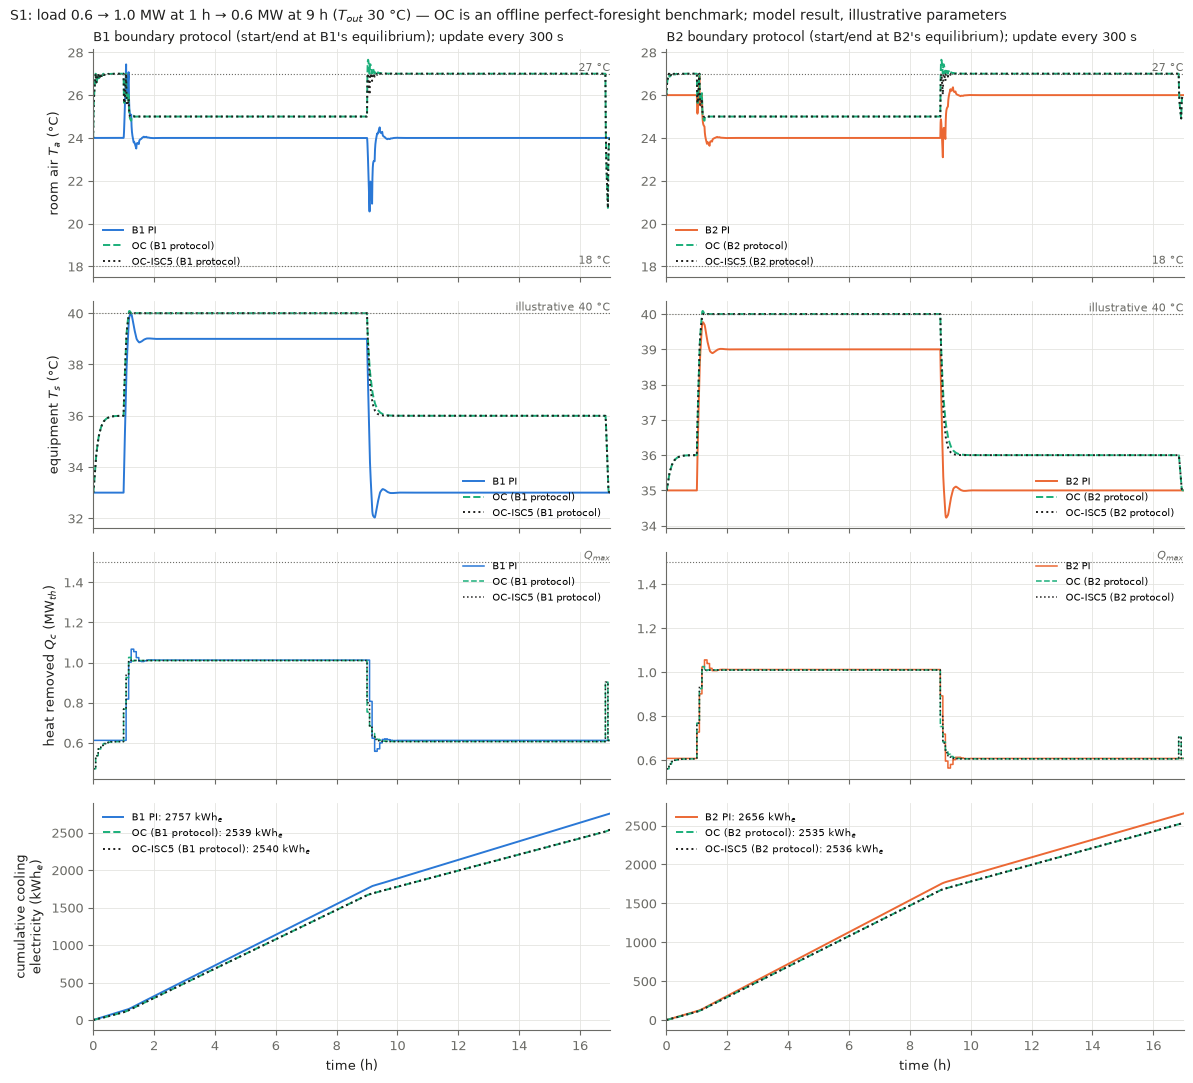

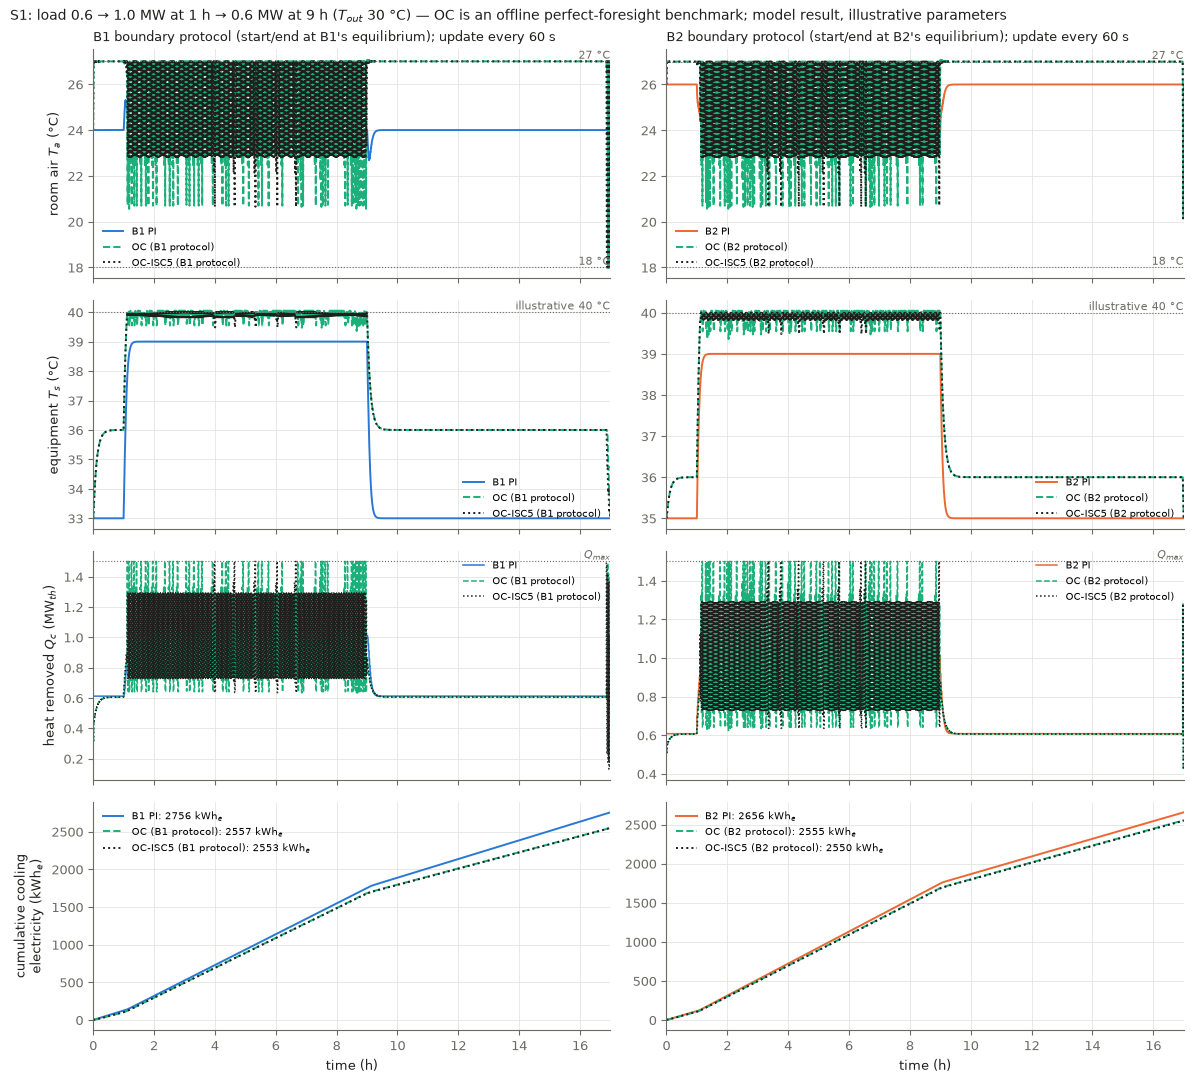

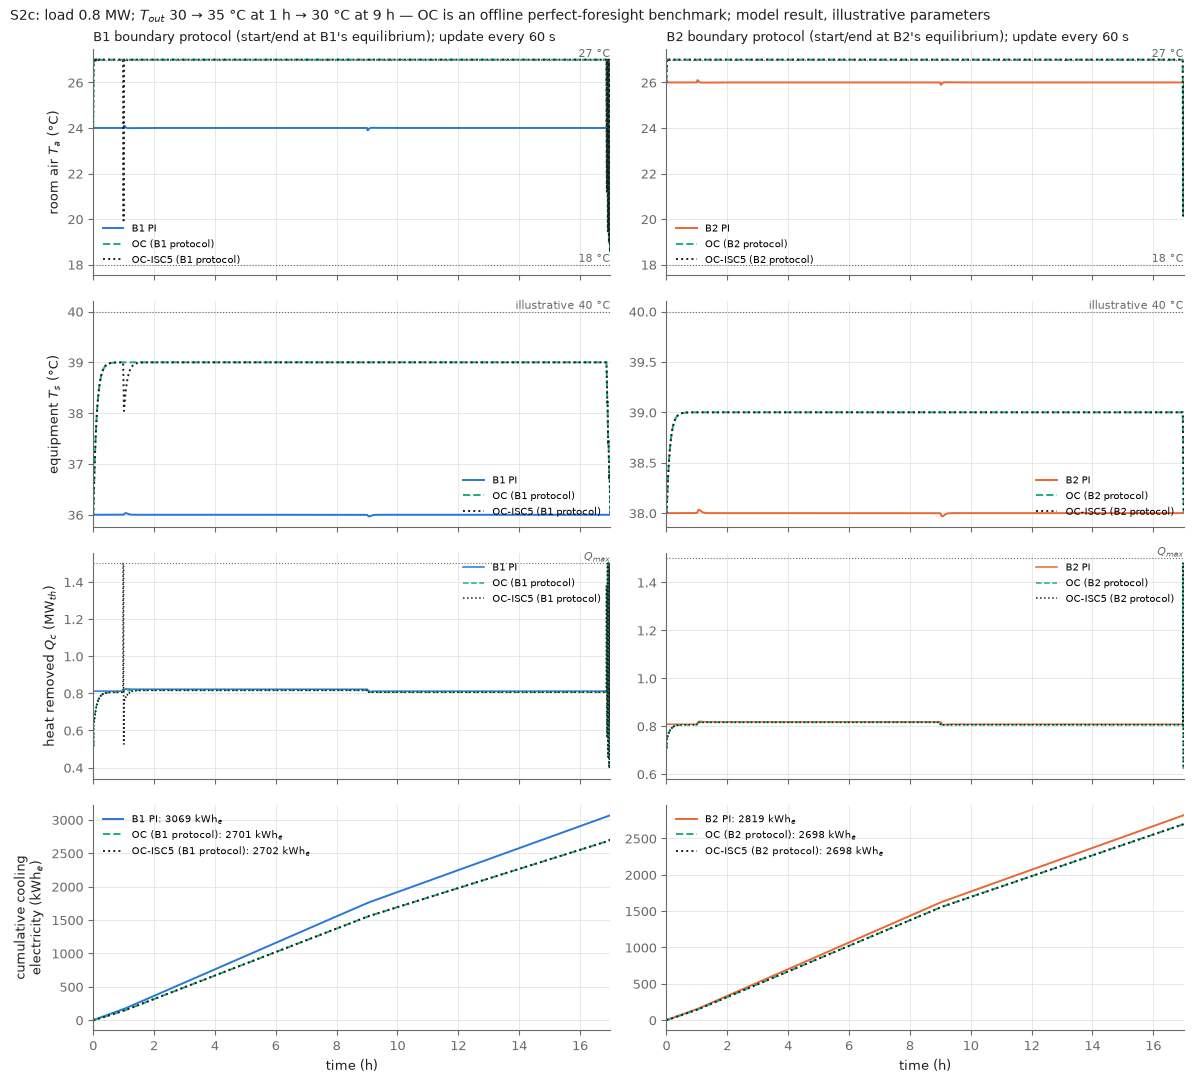

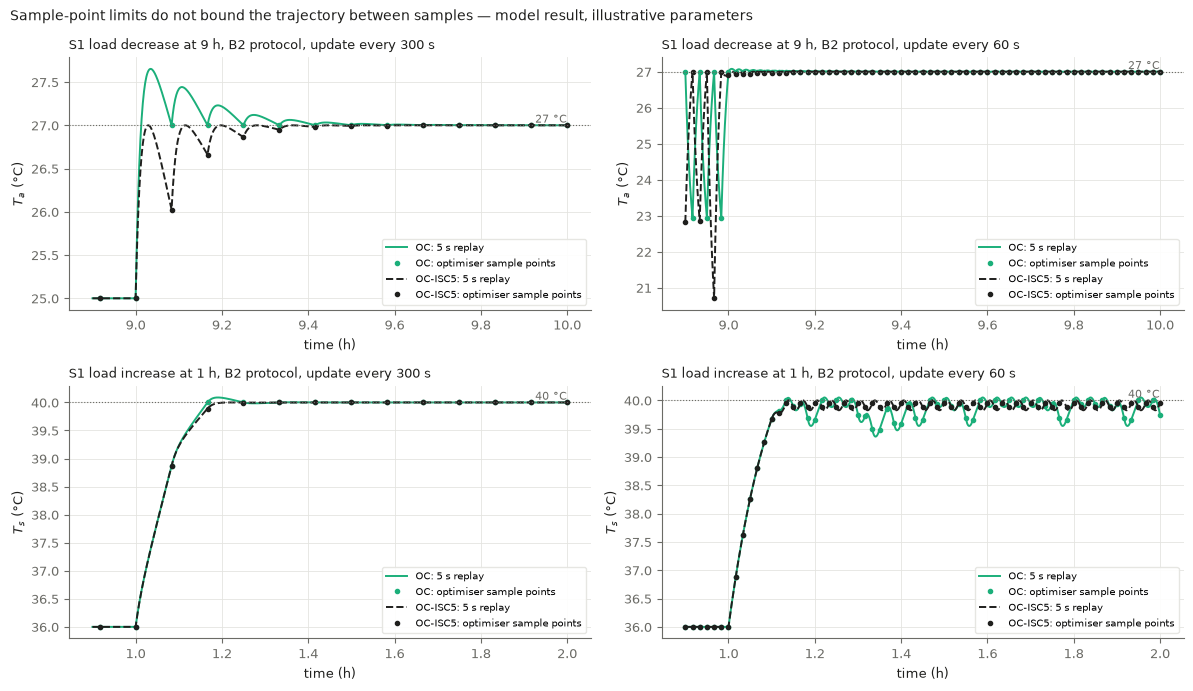

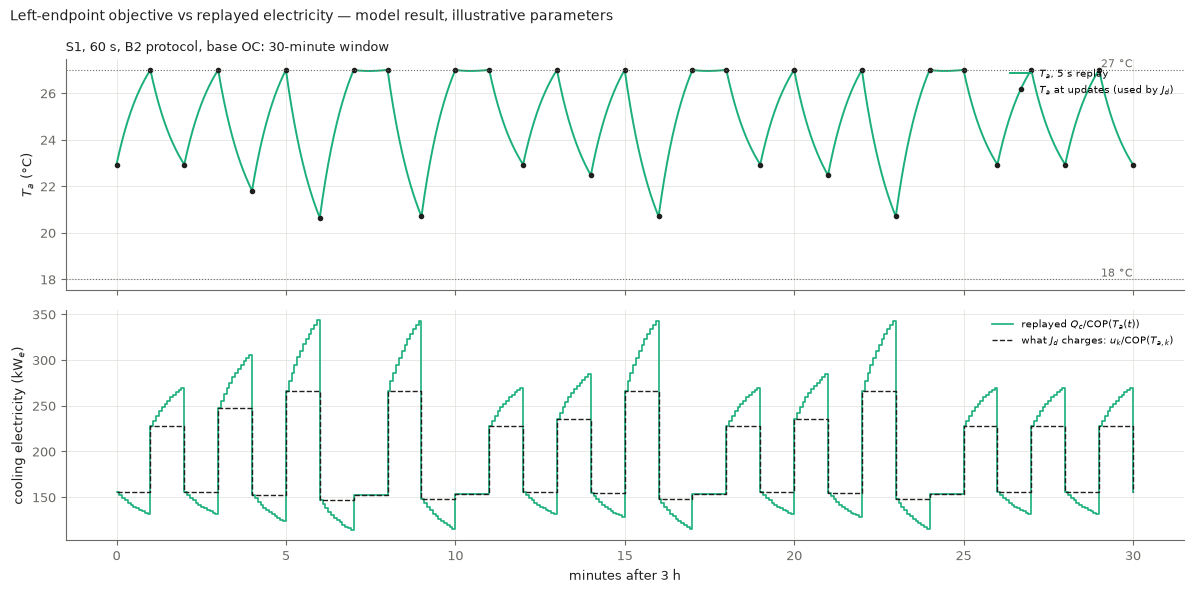

saved: fig10_oc_S1_60s.png fig11_oc_S2c_60s.png fig12_oc_intersample_zoom.png fig13_oc_60s_objective_vs_replay.png fig09_oc_S1_300s.png


In [12]:
BLUE, ORANGE, GREEN, INK, MUTED, GRID, RED = "#2a78d6", "#eb6834", "#1baf7a", "#1f1f1d", "#6b6b66", "#e4e4e0", "#c0392b"
plt.rcParams.update({"font.size": 9.5, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False})


def style(ax):
    ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)


def hline(ax, y, txt, x):
    ax.axhline(y, color=MUTED, lw=0.8, ls=":")
    if txt:
        ax.text(x, y, " " + txt, color=MUTED, fontsize=8, va="bottom", ha="right")


def oc_figure(sid, dt, fname):
    fig, axs = plt.subplots(4, 2, figsize=(12, 11), sharex=True)
    for j, kind in enumerate(("B1", "B2")):
        series = [(PI[(sid, dt, kind)], BLUE if kind == "B1" else ORANGE, "-", f"{kind} PI")]
        for var, col, ls in (("OC", GREEN, "--"), ("OC-ISC5", INK, ":")):
            if (sid, dt, kind, var) in A_OC:
                series.append((REP[(sid, dt, kind, var)], col, ls, f"{var} ({kind} protocol)"))
        for r, col, ls, lab in series:
            th = r.t / H
            axs[0, j].plot(th, r.X[:, 1], color=col, ls=ls, lw=1.4, label=lab)
            axs[1, j].plot(th, r.X[:, 0], color=col, ls=ls, lw=1.4, label=lab)
            axs[2, j].step(th, r.Q / 1e6, where="post", color=col, ls=ls, lw=1.1, label=lab)
            axs[3, j].plot(th, tm.J_to_kWh(r.E_cool), color=col, ls=ls, lw=1.4, label=f"{lab}: {tm.J_to_kWh(r.E_cool[-1]):.0f} kWh$_e$")
        hline(axs[0, j], 27.0, "27 °C", 17); hline(axs[0, j], 18.0, "18 °C", 17)
        hline(axs[1, j], 40.0, "illustrative 40 °C", 17); hline(axs[2, j], p.Q_max / 1e6, "$Q_{max}$", 17)
        axs[0, j].set_title(f"{kind} boundary protocol (start/end at {kind}'s equilibrium); update every {dt} s", loc="left", color=INK, fontsize=9)
        axs[3, j].set_xlabel("time (h)")
        for ax in axs[:, j]:
            ax.set_xlim(0, 17); style(ax)
    axs[0, 0].set_ylabel("room air $T_a$ (°C)"); axs[1, 0].set_ylabel("equipment $T_s$ (°C)")
    axs[2, 0].set_ylabel("heat removed $Q_c$ (MW$_{th}$)"); axs[3, 0].set_ylabel("cumulative cooling\nelectricity (kWh$_e$)")
    for i, loc in enumerate(("lower left", "lower right", "upper right", "upper left")):
        for ax in axs[i]:
            ax.legend(frameon=False, fontsize=7.5, loc=loc)
    fig.suptitle(CMP[sid]["title"] + " — OC is an offline perfect-foresight benchmark; model result, illustrative parameters",
                 x=0.01, ha="left", color=INK, fontsize=10)
    fig.tight_layout(); fig.savefig(FIG_DIR / fname, dpi=150); plt.show()


oc_figure("S1", 300, "fig09_oc_S1_300s.png")
oc_figure("S1", 60, "fig10_oc_S1_60s.png")
oc_figure("S2c", 60, "fig11_oc_S2c_60s.png")

# intersample zoom: base OC (sample-point limits only) vs OC-ISC5, around the S1 load increase, B2 protocol
fig, axs = plt.subplots(2, 2, figsize=(12, 7))
for j, dt in enumerate(DTS):
    for i, (state, lim, lab, t0, ev) in enumerate(((1, 27.0, "$T_a$ (°C)", 8.9, "load decrease at 9 h"),
                                                   (0, 40.0, "$T_s$ (°C)", 0.9, "load increase at 1 h"))):
        ax = axs[i, j]
        for var, col, ls in (("OC", GREEN, "-"), ("OC-ISC5", INK, "--")):
            key = ("S1", dt, "B2", var)
            if key not in REP:
                continue
            r, b = REP[key], CASES[key]["best"]
            z = (r.t >= t0 * H) & (r.t <= (t0 + 1.1) * H)
            ax.plot(r.t[z] / H, r.X[z, state], color=col, ls=ls, lw=1.4, label=f"{var}: 5 s replay")
            zk = (CASES[key]["prob"].t >= t0 * H) & (CASES[key]["prob"].t <= (t0 + 1.1) * H)
            ax.plot(CASES[key]["prob"].t[zk] / H, b.x[zk, state], ls="none", marker="o", ms=3, color=col, label=f"{var}: optimiser sample points")
        hline(ax, lim, f"{lim:.0f} °C", t0 + 1.1)
        ax.set_title(f"S1 {ev}, B2 protocol, update every {dt} s", loc="left", color=INK, fontsize=9)
        ax.set_xlabel("time (h)"); ax.set_ylabel(lab); style(ax)
        ax.legend(frameon=True, framealpha=0.92, edgecolor=GRID, fontsize=7.5, loc="lower right")
fig.suptitle("Sample-point limits do not bound the trajectory between samples — model result, illustrative parameters",
             x=0.01, ha="left", color=INK, fontsize=10)
fig.tight_layout(); fig.savefig(FIG_DIR / "fig12_oc_intersample_zoom.png", dpi=150); plt.show()

# 60 s: what the left-endpoint objective charges vs what the replay integrates
key = ("S1", 60, "B2", "OC")
if key in REP:
    r, b, prob = REP[key], CASES[key]["best"], CASES[key]["prob"]
    fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    z = (r.t >= 3 * H) & (r.t <= 3 * H + 1800)
    zk = (prob.t[:-1] >= 3 * H) & (prob.t[:-1] <= 3 * H + 1800)
    axs[0].plot((r.t[z] - 3 * H) / 60, r.X[z, 1], color=GREEN, lw=1.4, label="$T_a$, 5 s replay")
    axs[0].plot((prob.t[:-1][zk] - 3 * H) / 60, b.x[:-1][zk, 1], ls="none", marker="o", ms=3, color=INK, label="$T_a$ at updates (used by $J_d$)")
    hline(axs[0], 27.0, "27 °C", 30); hline(axs[0], 18.0, "18 °C", 30)
    axs[1].step((r.t[z] - 3 * H) / 60, r.P_cool[z] / 1e3, where="post", color=GREEN, lw=1.2, label="replayed $Q_c$/COP($T_a(t)$)")
    g_k = 1.0 / tm.cop(p, b.x[:-1][zk, 1], prob.T_out[zk])
    axs[1].step((prob.t[:-1][zk] - 3 * H) / 60, b.u_W[zk] * g_k / 1e3, where="post", color=INK, ls="--", lw=1.0,
                label="what $J_d$ charges: $u_k$/COP($T_{a,k}$)")
    axs[0].set_ylabel("$T_a$ (°C)"); axs[1].set_ylabel("cooling electricity (kW$_e$)"); axs[1].set_xlabel("minutes after 3 h")
    for ax in axs:
        style(ax); ax.legend(frameon=False, fontsize=7.5, loc="upper right")
    axs[0].set_title("S1, 60 s, B2 protocol, base OC: 30-minute window", loc="left", color=INK, fontsize=9)
    fig.suptitle("Left-endpoint objective vs replayed electricity — model result, illustrative parameters", x=0.01, ha="left", color=INK, fontsize=10)
    fig.tight_layout(); fig.savefig(FIG_DIR / "fig13_oc_60s_objective_vs_replay.png", dpi=150); plt.show()
print("saved:", *sorted(x.name for x in FIG_DIR.glob("fig1[0-3]*.png")), "fig09_oc_S1_300s.png")

### Interpretation
<div style="background:#fdf6e3;border-left:6px solid #c98500;padding:10px 14px;margin:6px 0;border-radius:4px;color:#1f1f1d">
<b>What the benchmark shows (model behaviour, illustrative parameters)</b><br>
<ol>
<li><b>Eligible signed savings on replayed electricity</b> (both runs within limits on the 5 s grid, terminal checks passed; this notebook's eligibility rule does not use the 1 s grid, see item 3).
<ul>
<li><b>OC vs B2</b>, the stronger baseline, B2 protocol: S2c +4.29 % (300 s) and +4.32 % (60 s); S1 +4.51 % (300 s) and +3.99 % (60 s). In S1 only the intersample-constrained variant OC-ISC5 is eligible, and these two S1 runs exceed a limit on the 1 s grid (by at most 4.8e-5 K at 300 s and 7.5e-4 K at 60 s), so they are <b>not continuously safe</b>.</li>
<li><b>OC vs B1</b>, B1 protocol: S2c +11.95 % (300 s) and +11.97 to +11.99 % (60 s); S1 +7.37 % (60 s, OC-ISC5 only; it exceeds a limit by up to 7.5e-4 K on the 1 s grid, so it is not continuously safe).</li>
<li>S1 at 300 s with the B1 protocol is <b>not</b> eligible: the B1 PI run itself exceeds 27 °C.</li>
<li>These are offline perfect-foresight benchmark numbers with illustrative parameters. They are not achievable savings for a real controller.</li>
</ul></li>
<li><b>Where the advantage comes from: holding the temperature at the limits, not clever timing.</b>
<ul>
<li>OC sits exactly on the limits, with zero margin: air at 27 °C, or, at 1.0 MW, the lumped equipment at 40 °C, which forces the air down to 25 °C.</li>
<li>A quasi-steady estimate at those limit temperatures (§7a) is 2536 kWh<sub>e</sub> for S1 and 2696 kWh<sub>e</sub> for S2c. The 300 s OC replays differ from it by −0.7 to +6.3 kWh<sub>e</sub>.</li>
<li>So OC's gain over B2 is essentially the price of B2's provisional 1 K margin. Its gain over B1 is mostly B1's fixed 24 °C setpoint (the setpoint effect the spec assigns to the sensitivity stage), not the value of optimisation.</li>
<li>Perfect foresight adds little here. This fits the spec's hypothesis that timing leverage is small, but it is <i>not</i> a proof or a bound.</li>
<li>Zero margin is exactly what a real facility would not run with.</li>
</ul></li>
<li><b>Sample-point limits are not enough.</b>
<ul>
<li>In S1 the base OC is feasible at every update, yet its replay exceeds the limits between updates: T<sub>a</sub> 27.65 °C and T<sub>s</sub> 40.09 °C at 300 s; 27.07–27.08 °C and 40.05 °C at 60 s. Those runs are not eligible.</li>
<li>The separately labelled variant OC-ISC5 also imposes the limits every 5 s, and is within the limits on the 5 s grid.</li>
<li>Its <i>discrete objective</i> J<sub>d</sub> is 0.9 kWh<sub>e</sub> (300 s) and 2.5 kWh<sub>e</sub> (60 s) higher than base OC's.</li>
<li>Its <i>replayed electricity</i> is 0.8–0.9 kWh<sub>e</sub> higher at 300 s, but <b>lower</b> at 60 s: 2553.3 vs 2556.9 kWh<sub>e</sub> (B1 protocol) and 2550.4 vs 2554.9 kWh<sub>e</sub> (B2 protocol). The base OC's J<sub>d</sub> advantage at 60 s comes from the left-endpoint artefact (item 4), not from using less electricity.</li>
<li>In S2c both variants give the same solution.</li>
<li>On a 1 s grid, OC-ISC5 in S1 still exceeds a limit between the 5 s points, by tiny amounts (exact values in §6): at most 4.8e-5 K for 22 s in total at 300 s, and at most 7.5e-4 K for about 10 min in total at 60 s. Eligibility here follows the declared 5 s rule, as in Stage 3. These runs are <b>not continuously safe</b>, and under the stricter 5 s <i>and</i> 1 s rule of notebook 05 they would not be eligible.</li>
</ul></li>
<li><b>J<sub>d</sub> and replayed electricity differ in size at 60 s</b> (the direction agrees in every row).
<ul>
<li>At 300 s, J<sub>d</sub> is within 0.1–1.4 kWh<sub>e</sub> of the replay.</li>
<li>At 60 s in S1, J<sub>d</sub> is about 48–56 kWh<sub>e</sub> lower. The optimiser switches cooling every minute (fig13): it cools hard in intervals that <i>start</i> at 27 °C, where J<sub>d</sub> charges the best COP, while the air actually drops to about 21–23 °C within the minute.</li>
<li>So the J<sub>d</sub> saving overstates the electricity saving: 9.17 vs 7.37 % against B1, and 5.78 vs 3.99 % against B2.</li>
<li>The switching also nearly doubles peak cooling power (about 350–380 vs about 205–210 kW<sub>e</sub>). It is an artefact of the left-endpoint objective, not a sensible operating pattern. A midpoint or Simpson objective, or a rate penalty, would address it; neither was implemented.</li>
</ul></li>
<li><b>How close to optimal?</b>
<ul>
<li>S2c: the certified LP gap is 0.09–0.24 %, so the best-found J<sub>d</sub> is within that of the optimum of P<sub>d</sub>.</li>
<li>S1: the gap is 4.1–5.7 %. The bound is loose because it charges COP at 27 °C, while at 1.0 MW the 40 °C equipment limit keeps the air at about 25 °C. It therefore says little about optimality in S1.</li>
<li>Multistart spreads are 0 to 0.07 % at 300 s and up to 0.9 % at 60 s. Different starts reach different command sequences (up to about 1.5 MW apart in individual intervals), so the 60 s solutions are local and non-unique. The results are best-found, not global.</li>
</ul></li>
<li><b>Solver issues (all logged, none hidden).</b>
<ul>
<li>SciPy's default HiGHS path returned status 4 ("Not Set") on some LPs, and HiGHS IPM once returned "Unknown". Every LP bound is certified independently by weak duality from a configuration that did solve.</li>
<li>In this run, every IPOPT start reported Solve_Succeeded and was independently feasible.</li>
<li>In an earlier run, slowed by a second concurrent execution of this notebook, two perturbed 60 s OC-ISC5 starts stopped at the wall-time limit. So the 300 s per-solve budget is not generous under load.</li>
</ul></li>
<li><b>The constant-COP invariance test passes</b> (UA<sub>e</sub> = 0, frozen COP). PI, OC replay, J<sub>d</sub> and the LP bound all equal E<sub>IT</sub>/COP to about 1e-13, so no saving is manufactured by the pipeline.</li>
</ol>
<b>Not shown here, all of which could change the conclusions:</b>
<ul>
<li>imperfect forecasts (the MPC bonus stage);</li>
<li>a safety margin for OC;</li>
<li>κ &gt; 0;</li>
<li>real COP curves and fan power;</li>
<li>parameter uncertainty;</li>
<li>any real facility.</li>
</ul>

</div>

## 10. Summary (copyable)

In [13]:
groups = [
    ("Re-created PI runs reproduce Stage 3", r"PI0"),
    ("Problem rows reproduce Stage 1 simulate_zoh (incl. intersample rows)", r"DYN"),
    ("NLP 1/COP expression = thermal_model.cop", r"GX"),
    ("LP coefficient is a valid minimum over the whole band", r"LB"),
    ("LP and NLP share matrices/rhs/bounds (Jacobian = A)", r"L5"),
    ("LP: optimal, configurations agree, dual certificate, feasible", r"LP"),
    ("NLP best-found: status, independent feasibility, objective", r"NLP"),
    ("Certified J_LB <= best-found J_d", r"BND"),
    ("J_d(OC) <= J_d(PI) where PI is feasible for P_d", r"PIJ"),
    ("Replay states at updates = optimiser states", r"RP"),
    ("Replay energy balance; heat removed = sum(Q h)", r"RE"),
    ("Replay grid refinement 5 s vs 1 s", r"RG"),
    ("Independent electricity quadrature on replays", r"RQ"),
    ("Replay terminal state and dU", r"RT"),
    ("Constant-COP invariance (UA_e = 0): gains stable", r"INV0"),
    ("Constant-COP invariance (UA_e = 0): no apparent saving", r"INV"),
]
lines = ["STAGE 4 (perfect-foresight benchmark) VERIFICATION SUMMARY (fresh kernel)", "-" * 78]
used = set()
for name, pat in groups:
    rows = [r for r in results if re.fullmatch(pat + r"(-.*)?", r[0])]
    used |= {r[0] for r in rows}
    n_ok = sum(r[4] for r in rows)
    lines.append(f"{'PASS' if rows and n_ok == len(rows) else 'FAIL'}  {name:64s} {n_ok:3d}/{len(rows):3d}")
assert used == {r[0] for r in results}, f"ungrouped: {set(r[0] for r in results) - used}"
lines += ["-" * 78, f"TOTAL {sum(r[4] for r in results)}/{len(results)} checks passed"]
failed = [r for r in results if not r[4]]
lines += ["UNRESOLVED FAILURES: " + ("none" if not failed else "")] + [f"  FAIL {r[0]}: {r[1]} | measured {r[2]} | criterion {r[3]}" for r in failed]
elapsed = (time.perf_counter() - T_NB_START) / 60
lines += ["", f"solve wall time: 300 s problems {SOLVE_TIME[300]:.0f} s, 60 s problems {SOLVE_TIME[60]:.0f} s; whole notebook {elapsed:.1f} min "
          f"(budget {STAGE_BUDGET_MIN:.0f} min: {'within' if elapsed <= STAGE_BUDGET_MIN else 'EXCEEDED'})", ""]
lines += TAB + [""] + CTXT + [""] + [f"FINDING {fid}: {txt}" for fid, txt in findings]
print("\n".join(lines))

STAGE 4 (perfect-foresight benchmark) VERIFICATION SUMMARY (fresh kernel)
------------------------------------------------------------------------------
PASS  Re-created PI runs reproduce Stage 3                               8/  8
PASS  Problem rows reproduce Stage 1 simulate_zoh (incl. intersample rows)  16/ 16
PASS  NLP 1/COP expression = thermal_model.cop                           1/  1
PASS  LP coefficient is a valid minimum over the whole band              8/  8
PASS  LP and NLP share matrices/rhs/bounds (Jacobian = A)               16/ 16
PASS  LP: optimal, configurations agree, dual certificate, feasible     16/ 16
PASS  NLP best-found: status, independent feasibility, objective        16/ 16
PASS  Certified J_LB <= best-found J_d                                  16/ 16
PASS  J_d(OC) <= J_d(PI) where PI is feasible for P_d                   14/ 14
PASS  Replay states at updates = optimiser states                       16/ 16
PASS  Replay energy balance; heat removed = sum(Q h) 